# Milestone 3. Từ hiểu dữ liệu đến chuẩn bị dữ liệu

**Nhóm N02**, học phần Khoa học Phân tích Dữ liệu, Khoa Công nghệ Thông tin, Trường Đại học Khoa học Tự nhiên, ĐHQG-HCM.
Thành viên: Ngô Triệu Gia Gia (25C11037), Trần Duy Khương (25C12004), Nguyễn Hoàng Nhật Quang (25C12033).
Giảng viên phụ trách: TS. Nguyễn Trần Minh Thư.

Notebook này là phần mã nguồn đi kèm báo cáo Milestone 3. Notebook đi từ tệp dữ liệu thô đã thu thập ở Milestone 2 đến **Prepared Dataset v1.0**, sau đó thực hiện phân tích khám phá (EDA) để trả lời từng Analytical Question ở mức phù hợp với dữ liệu.

**Cấu trúc notebook**

| Phần | Nội dung | Mục tương ứng trong báo cáo |
|---|---|---|
| 1 | Thiết lập môi trường và nạp tệp dữ liệu thô | Mục 1 |
| 2 | Hằng số cấu hình và quy tắc miền | Mục 5, Mục 6 |
| 3 | Pipeline chuẩn bị dữ liệu, chín bước có nhật ký biến đổi | Mục 6 |
| 4 | Đóng gói sản phẩm, từ điển dữ liệu, lineage và nhật ký chất lượng | Mục 6, Mục 8 |
| 5 | Kiểm định sau xử lý | Mục 6.5 |
| 6 | Phân tích khám phá AQ1 đến AQ7 | Mục 3, Mục 4, Mục 7 |
| 7 | Kiểm tra tái lập và tóm tắt kết quả | Phụ lục |

**Nguyên tắc thiết kế**

1. Dữ liệu thô bất biến: tệp chỉ được mở ở chế độ đọc và được đối chiếu SHA-256 với Milestone 2.
2. Mọi quyết định xử lý dựa trên quy tắc miền giáo dục hoặc bằng chứng về chất lượng, không dựa vào hiệu năng mô hình. Notebook không huấn luyện mô hình dự báo.
3. Các phép biến đổi cần học tham số từ dữ liệu (chuẩn hóa, điền khuyết theo thống kê) **không** được thực hiện ở đây. Chúng chỉ được đặc tả và sẽ được fit riêng trong từng fold huấn luyện ở Milestone 4, nhằm tránh rò rỉ thông tin từ phần kiểm tra sang phần huấn luyện.
4. Mọi thao tác được ghi vào nhật ký biến đổi để truy vết nguồn gốc của từng biến.

**Cách chạy.** Trên Google Colab chọn *Runtime → Run all*. Tệp dữ liệu thô được nhúng sẵn ở Mục 1.2, không cần tải lên. Thời gian chạy khoảng một đến hai phút.

## Đọc trước khi chạy (dành cho giảng viên và các thành viên trong nhóm)

**Cách chạy (3 bước, không cần cài đặt gì):**
1. Mở [Google Colab](https://colab.research.google.com), chọn *File → Upload notebook* và chọn tệp này (hoặc mở tệp từ Google Drive bằng *Open with → Google Colaboratory*).
2. Chọn *Runtime → Run all* (Thời gian chạy → Chạy tất cả).
3. Đợi các ô chạy từ trên xuống dưới, tổng cộng khoảng **1 đến 2 phút**. Không cần tải dữ liệu lên, không cần Google Drive, không cần cài thêm thư viện, **không tốn phí** (Colab miễn phí là đủ, không cần GPU).

**Toàn bộ chương trình nằm trong các ô của notebook này.** Không có tệp `.py` hay thư mục mã nguồn đi kèm; nhóm không cần triển khai trên máy cá nhân.

**Notebook này làm gì?** Đi từ tệp dữ liệu gốc đến *Prepared Dataset v1.0* (bảng dữ liệu đã làm sạch, có nhật ký từng bước biến đổi), rồi phân tích khám phá (EDA) để trả lời các câu hỏi AQ1 đến AQ3 và chuẩn bị cho AQ4 đến AQ7.

**Dữ liệu lấy ở đâu?** Tệp dữ liệu gốc `Students_Performance_data_set.xlsx` (187 KB, công khai trên Mendeley Data, DOI 10.17632/dc3797vf3t.1, giấy phép CC BY 4.0 cho phép phân phối lại khi ghi nguồn) được **nhúng ngay trong một ô của notebook** dưới dạng một chuỗi chữ dài (đã nén bằng zlib và mã hóa base64; ô này được thu gọn, bấm để xem). Khi chạy, ô kế tiếp giải chuỗi đó thành tệp Excel trong bộ nhớ tạm của Colab. Vì vậy notebook không tải gì từ internet và vẫn chạy được nếu đường dẫn trên Mendeley thay đổi.

**Mã băm SHA-256 là gì?** Đó là "dấu vân tay" của một tệp: một chuỗi 64 ký tự được tính từ nội dung tệp. Chỉ cần đổi một ký tự trong tệp thì dấu vân tay thay đổi hoàn toàn. Notebook tính lại dấu vân tay của tệp vừa giải nén và so với giá trị đã ghi sẵn; nếu khớp thì đúng là tệp nhóm đã dùng, không bị sửa hay hỏng. Với các tệp kết quả, nếu thư viện Colab khác phiên bản (ví dụ cách ghi số thập phân), dấu vân tay có thể khác dù nội dung không đổi; vì thế ngoài dấu vân tay, notebook còn kiểm tra trực tiếp các con số quan trọng (số dòng, số ca dương, các chỉ số trong báo cáo).

**Tệp tạo ra nằm ở đâu?** Trong thư mục tạm `/content/` của phiên Colab (bấm biểu tượng thư mục ở thanh bên trái để xem hoặc tải về). Thư mục này bị xóa khi phiên kết thúc; chạy lại notebook sẽ tạo lại y hệt.

**Nếu một ô báo lỗi:** chọn *Runtime → Restart session and run all* để chạy lại từ đầu (các ô phụ thuộc nhau theo thứ tự, không nên chạy riêng lẻ ở giữa).

## 1. Thiết lập môi trường

### 1.1. Thư viện và thư mục làm việc

Notebook dùng `pandas`, `numpy`, `scipy`, `scikit-learn` và `matplotlib`, đều có sẵn trên Colab. Cấu trúc thư mục bám theo gói dữ liệu đã nộp: `data/raw` (tệp gốc, chỉ đọc), `data/interim` (bảng trung gian đã chuẩn hóa kiểu), `data/processed` (bảng phân tích), `data/metadata` (từ điển dữ liệu, lineage, nhật ký) và `reports/milestone3` (bảng, hình của EDA).

In [1]:
import hashlib
import json
import platform
import re
import warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter
from scipy import stats
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 90)

BASE = Path("/content") if Path("/content").exists() else Path.cwd()
ROOT = BASE / "N02_Milestone3"
raw_path = ROOT / "data" / "raw" / "Students_Performance_data_set.xlsx"
interim = ROOT / "data" / "interim"
processed = ROOT / "data" / "processed"
meta = ROOT / "data" / "metadata"
FIG = ROOT / "reports" / "milestone3" / "figures"
TAB = ROOT / "reports" / "milestone3" / "tables"
for d in (raw_path.parent, interim, processed, meta, FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)

print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__)
print("Thư mục gốc:", ROOT)

Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | scipy 1.16.3 | scikit-learn 1.6.1
Thư mục gốc: /content/N02_Milestone3


### 1.2. Nạp tệp dữ liệu thô

Tệp `Students_Performance_data_set.xlsx` (Mendeley Data, DOI 10.17632/dc3797vf3t.1, giấy phép CC BY 4.0) được nhúng nguyên văn trong ô dưới đây. Mã băm SHA-256 được kiểm tra khi giải nén và phải trùng với giá trị đã ghi trong nhật ký thu thập của Milestone 2.

In [2]:
#@title Ghi tệp dữ liệu thô nhúng sẵn vào data/raw (bấm để xem mã)
import base64, hashlib, zlib

EMBEDDED_FILES = {
    "data/raw/Students_Performance_data_set.xlsx": {
        "sha256": "04ebaf9f3a047afe96d9bff22dbe65b2a320e6395f230032735495e7e58277cf",
        "data": (
            "..."
        ),
    },
}

for rel, item in EMBEDDED_FILES.items():
    target = ROOT / rel
    target.parent.mkdir(parents=True, exist_ok=True)
    raw = zlib.decompress(base64.b64decode(item["data"]))
    digest = hashlib.sha256(raw).hexdigest()
    assert digest == item["sha256"], f"Tệp {rel} bị hỏng khi giải nén"
    if target.exists():
        target.chmod(0o644)
    target.write_bytes(raw)
    print(f"{rel}: {len(raw):,} byte".replace(",", ".") + f", SHA-256 {digest[:16]}... khớp bản gốc")

data/raw/Students_Performance_data_set.xlsx: 187.253 byte, SHA-256 04ebaf9f3a047afe... khớp bản gốc


## 2. Hằng số cấu hình và quy tắc miền

Các hằng số dưới đây được cố định trước khi xử lý và không được học từ dữ liệu:

* **Kiểm tra tệp:** mã băm SHA-256 và kích thước 1.194 × 31 của Milestone 2.
* **Ngưỡng nhãn:** ngưỡng chính CGPA < 2,75 và hai ngưỡng độ nhạy 2,50 và 3,00.
* **Cặp giá trị lặp bất thường:** 140 dòng có cùng cặp SGPA 2,68 và CGPA 3,15 ở mọi học kỳ, được phát hiện ở bước profiling.
* **Ngưỡng miền:** chương trình BCSE chuẩn có 12 học kỳ; một hoạt động không vượt quá 16 giờ mỗi ngày; tổng giờ học, mạng xã hội và phát triển kỹ năng hợp lý không quá 18 giờ; chuyên cần dưới 50% được gắn cờ rà soát.
* **Danh sách vai trò biến:** biến rò rỉ (hệ quả hoặc thành phần của CGPA), biến quan hệ ngược chiều, biến nhạy cảm bị loại và biến chỉ dùng để kiểm định công bằng, theo Mục 2.5 và Mục 8.2 của báo cáo Milestone 2.
* **Tập đặc trưng lõi:** 5 biến thói quen học tập (AQ2) và 8 cột điều kiện, bối cảnh học tập (AQ3), tương ứng 12 mục khảo sát vì trình độ tiếng Anh được mã hóa bằng hai biến giả.

In [3]:
EXPECTED_SHA256 = "04ebaf9f3a047afe96d9bff22dbe65b2a320e6395f230032735495e7e58277cf"
EXPECTED_SHAPE = (1194, 31)
RANDOM_STATE = 42
N_FOLDS = 5

THRESHOLDS = {"y_lt_2_50": 2.50, "y_lt_2_75": 2.75, "y_lt_3_00": 3.00}
PRIMARY_TARGET = "y_lt_2_75"

# Cặp giá trị lặp bất thường (140 dòng) phát hiện ở bước profiling
PLACEHOLDER_SGPA = 2.68
PLACEHOLDER_CGPA = 3.15

# Ngưỡng miền (không học từ dữ liệu)
MAX_STANDARD_SEMESTER = 12      # chương trình BCSE chuẩn gồm 12 học kỳ
MAX_DAILY_HOURS = 16            # giới hạn giờ thức tối đa mỗi ngày cho một hoạt động
TIME_BUDGET_LIMIT = 18          # tổng giờ học + mạng xã hội + kỹ năng tối đa hợp lý
LOW_ATTENDANCE_LIMIT = 50       # chuyên cần dưới 50% được gắn cờ để rà soát

RAW_COLUMNS = [
    "University Admission year",
    "Gender",
    "Age",
    "H.S.C passing year",
    "Program",
    "Current Semester",
    "Do you have meritorious scholarship ?",
    "Do you use University transportation?",
    "How many hour do you study daily?",
    "How many times do you seat for study in a day?",
    "What is your preferable learning mode?",
    "Do you use smart phone?",
    "Do you have personal Computer?",
    "How many hour do you spent daily in social media?",
    "Status of your English language proficiency",
    "Average attendance on class",
    "Did you ever fall in probation?",
    "Did you ever got suspension?",
    "Do you attend in teacher consultancy for any kind of academical problems?",
    "What are the skills do you have ?",
    "How many hour do you spent daily on your skill development?",
    "What is you interested area?",
    "What is your relationship status?",
    "Are you engaged with any co-curriculum activities?",
    "With whom you are living with?",
    "Do you have any health issues?",
    "What was your previous SGPA?",
    "Do you have any physical disabilities?",
    "What is your current CGPA?",
    "How many Credit did you have completed?",
    "What is your monthly family income?",
]

COLUMN_MAP = dict(zip(RAW_COLUMNS, [
    "admit_year", "gender", "age", "hsc_year", "program", "semester",
    "scholarship", "transport", "study_hours", "study_sessions", "learning_mode",
    "smartphone", "pc", "social_hours", "english", "attendance", "probation",
    "suspension", "consultancy", "skills", "skill_hours", "interest_area",
    "relationship", "cocurricular", "living_with", "health_issue", "prev_sgpa",
    "disability", "cgpa", "credits_completed", "family_income",
]))

# Danh sách biến theo vai trò (căn cứ Đề cương Mục 10.4, 10.5 và Milestone 2 Mục 6.2)
LEAKAGE_COLUMNS = ["prev_sgpa", "probation", "suspension", "scholarship"]
REVERSE_DIRECTION_COLUMNS = ["consultancy"]            # chỉ dùng chẩn đoán
SENSITIVE_DROP_COLUMNS = ["family_income", "health_issue", "disability", "relationship"]
AUDIT_ONLY_COLUMNS = ["gender", "living_with"]         # chỉ kiểm định công bằng

CORE_AQ2 = ["study_hours", "study_sessions", "attendance_pct", "social_hours", "skill_hours"]
CORE_AQ3 = ["learning_mode_online", "has_pc", "uses_transport", "english_basic", "english_advance",
            "semester_capped", "credits_completed", "cocurricular"]   # 7 mục khảo sát, 8 cột (tiếng Anh = 2 biến giả)
CORE_FEATURES = CORE_AQ2 + CORE_AQ3
DERIVED_CANDIDATES = ["credits_per_semester", "study_hours_per_session", "study_minus_social"]
OPTIONAL_NOISY = ["skills_group", "interest_group"]

### 2.1. Tiện ích dùng chung

`TransformationLog` ghi lại từng bước xử lý (số dòng vào, số dòng ra, số giá trị bị thay đổi) để tạo bảng lineage. `sha256_of` tính mã băm theo khối. `yes_no_to_int` quy đổi các câu trả lời Yes/No không thống nhất về 1/0 và để giá trị lạ thành khuyết thay vì đoán.

In [4]:
class TransformationLog:
    """Ghi lại từng bước xử lý để phục vụ truy vết nguồn gốc dữ liệu."""

    def __init__(self) -> None:
        self.rows: list[dict] = []

    def add(self, step: str, description: str, rows_in: int, rows_out: int,
            n_changed: int | None = None) -> None:
        self.rows.append({
            "step": step, "description": description, "rows_in": rows_in,
            "rows_out": rows_out, "n_values_changed": n_changed,
        })

    def to_frame(self) -> pd.DataFrame:
        return pd.DataFrame(self.rows)


def sha256_of(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def yes_no_to_int(s: pd.Series) -> pd.Series:
    """Quy đổi Yes/No (không phân biệt hoa thường) về 1/0; giá trị lạ thành NA."""
    m = s.astype("string").str.strip().str.lower().map({"yes": 1, "y": 1, "no": 0, "n": 0})
    return m.astype("Int64")

## 3. Pipeline chuẩn bị dữ liệu

Pipeline gồm chín bước, mỗi bước là một hàm nhận bảng dữ liệu và nhật ký, trả về bảng mới mà không sửa bảng đầu vào. Mỗi bước được định nghĩa, chạy và kiểm tra kết quả ngay sau đó.

In [5]:
log = TransformationLog()
raw_df = pd.read_excel(raw_path, sheet_name="Students_Performance_data_set")
print("Bảng thô dùng để đối chiếu nhật ký chất lượng:", raw_df.shape)

Bảng thô dùng để đối chiếu nhật ký chất lượng: (1194, 31)


### 3.1. Bước 1: nạp tệp và kiểm tra giả định về tệp

Bước đầu tiên dừng pipeline nếu tệp không trùng với bản đã thu thập ở Milestone 2 (mã băm, kích thước hoặc danh sách tên cột khác). Đây là cổng kiểm soát để mọi kết quả phía sau gắn với đúng một phiên bản dữ liệu.

In [6]:
def step1_load_and_validate(raw_path: Path, log: TransformationLog) -> pd.DataFrame:
    """Bước 1: nạp tệp thô ở chế độ đọc và kiểm tra giả định về tệp và schema."""
    digest = sha256_of(raw_path)
    if digest != EXPECTED_SHA256:
        raise ValueError(f"SHA-256 không khớp Milestone 2: {digest}")
    df = pd.read_excel(raw_path, sheet_name="Students_Performance_data_set")
    if df.shape != EXPECTED_SHAPE:
        raise ValueError(f"Kích thước {df.shape} khác kỳ vọng {EXPECTED_SHAPE}")
    if list(df.columns) != RAW_COLUMNS:
        raise ValueError("Tên cột không khớp schema đã ghi ở Milestone 2")
    log.add("S1_load", "Nạp tệp thô, đối chiếu SHA-256, kích thước 1194x31 và tên 31 cột",
            len(df), len(df))
    return df


df = step1_load_and_validate(raw_path, log)
print(df.shape)

(1194, 31)


### 3.2. Bước 2: đổi tên cột và tạo mã dòng

Tên cột gốc là nguyên văn câu hỏi khảo sát nên được đổi sang dạng `snake_case`. Vì tệp không có khóa định danh, nhóm tạo `rid` theo thứ tự dòng và ghi rõ giả định mỗi dòng là một sinh viên.

In [7]:
def step2_rename_and_rowid(df: pd.DataFrame, log: TransformationLog) -> pd.DataFrame:
    """Bước 2: đổi tên cột sang dạng snake_case và tạo mã dòng rid (không có khóa gốc)."""
    out = df.rename(columns=COLUMN_MAP).copy()
    out.insert(0, "rid", np.arange(1, len(out) + 1))
    log.add("S2_rename", "Đổi tên 31 cột, thêm rid = thứ tự dòng trong tệp thô (giả định mỗi dòng "
            "là một sinh viên vì không có khóa định danh)", len(df), len(out))
    return out


df = step2_rename_and_rowid(df, log)
display(df.head(3))

,rid,admit_year,gender,age,hsc_year,program,semester,scholarship,transport,study_hours,study_sessions,learning_mode,smartphone,pc,social_hours,english,attendance,probation,suspension,consultancy,skills,skill_hours,interest_area,relationship,cocurricular,living_with,health_issue,prev_sgpa,disability,cgpa,credits_completed,family_income
0,1,2018,Male,24,2016,BCSE,12,Yes,No,3,2,Offline,Yes,Yes,5,Intermediate,90,No,No,Yes,Software Development,2,Data Schince,Single,Yes,Bachelor,No,2.68,No,3.15,75,25000
1,2,2021,Male,22,2020,BCSE,4,Yes,Yes,3,2,Online,Yes,Yes,3,Basic,96,Yes,No,No,Web development,2,Event management,Single,Yes,Family,No,2.68,No,3.15,36,100000
2,3,2020,Female,21,2019,BCSE,5,No,No,3,3,Offline,Yes,Yes,3,Intermediate,80,No,No,Yes,Programming,1,Software,Single,No,Bachelor,No,2.68,No,3.15,50,50000


### 3.3. Bước 3: chuẩn hóa kiểu dữ liệu và nhãn phân loại

* **Chuyên cần:** cột bị đọc thành kiểu object do một ô dạng khoảng `94-98`; giá trị khoảng được quy về trung điểm và gắn cờ `attendance_range_flag`.
* **Biến nhị phân:** các câu trả lời Yes/No được mã hóa 1/0; hình thức học ưa thích được mã hóa `learning_mode_online`.
* **Trình độ tiếng Anh:** quan hệ với nhãn có dạng chữ U (Basic và Advance đều có tỷ lệ cần hỗ trợ cao hơn Intermediate), nên biến không được mã hóa thứ bậc cho mô hình mà dùng hai biến giả với Intermediate làm nhóm tham chiếu. Biến thứ bậc `english_level` chỉ được giữ để mô tả.
* **Nhãn không chuẩn hóa** ở các biến nhạy cảm được thống nhất, dù các biến này không đi vào tập đặc trưng.
* **Trường văn bản tự do** (kỹ năng 55 giá trị, lĩnh vực quan tâm 25 giá trị) được gom nhóm bằng quy tắc từ khóa và chỉ giữ ở vai trò tùy chọn do nhiễu cao.

In [8]:
def step3_standardize_types(df: pd.DataFrame, log: TransformationLog) -> pd.DataFrame:
    """Bước 3: chuẩn hóa kiểu dữ liệu và nhãn phân loại."""
    out = df.copy()

    # 3a. Chuyên cần: cột bị đọc thành object vì có ô dạng khoảng "94-98"
    raw_att = out["attendance"].astype("string").str.strip()
    is_range = raw_att.str.match(r"^\d+(\.\d+)?\s*-\s*\d+(\.\d+)?$", na=False)

    def parse_att(v: str) -> float:
        if v is pd.NA or v is None:
            return np.nan
        nums = [float(x) for x in re.findall(r"\d+(?:\.\d+)?", str(v))]
        return float(np.mean(nums)) if nums else np.nan

    out["attendance_pct"] = raw_att.map(parse_att).astype(float)
    out["attendance_range_flag"] = is_range.astype(int)
    log.add("S3a_attendance", "Quy đổi chuyên cần về số; ô dạng khoảng lấy trung điểm (94-98 thành 96) "
            "và gắn cờ attendance_range_flag", len(out), len(out), int(is_range.sum()))

    # 3b. Nhãn Yes/No về 0/1
    for src, dst in [("transport", "uses_transport"), ("smartphone", "has_smartphone"),
                     ("pc", "has_pc"), ("cocurricular", "cocurricular_bin"),
                     ("scholarship", "scholarship_bin"), ("probation", "probation_bin"),
                     ("suspension", "suspension_bin"), ("consultancy", "consultancy_bin")]:
        out[dst] = yes_no_to_int(out[src])
    out["cocurricular"] = out["cocurricular_bin"]
    out["learning_mode_online"] = (out["learning_mode"].str.strip().str.lower() == "online").astype(int)
    out["english_level"] = out["english"].str.strip().map(
        {"Basic": 0, "Intermediate": 1, "Advance": 2}).astype(int)
    # Quan hệ giữa tiếng Anh và nhãn có dạng chữ U (xem EDA, AQ3) nên không mã hóa thứ bậc cho mô hình.
    # Dùng hai biến giả với Intermediate làm nhóm tham chiếu.
    out["english_basic"] = (out["english_level"] == 0).astype(int)
    out["english_advance"] = (out["english_level"] == 2).astype(int)
    log.add("S3b_binary", "Mã hóa Yes/No thành 1/0; learning_mode_online (Online = 1); english_level "
            "(Basic 0, Intermediate 1, Advance 2) chỉ giữ để mô tả; tiếng Anh vào mô hình bằng hai biến giả "
            "english_basic và english_advance (tham chiếu Intermediate)", len(out), len(out))

    # 3c. Chuẩn hóa nhãn không nhất quán ở các biến nhạy cảm (chỉ phục vụ kiểm toán)
    health_before = out["health_issue"].astype("string")
    rel_before = out["relationship"].astype("string")
    h = health_before.str.strip().str.lower().replace({"n": "no"})
    out["health_issue"] = h.str.capitalize()
    out["relationship"] = out["relationship"].replace({"In a relationship": "Relationship"})
    n_cat = int((health_before != out["health_issue"]).sum() + (rel_before != out["relationship"]).sum())
    log.add("S3c_labels", "Chuẩn hóa health_issue (Yes/yes/no/N thành Yes/No) và gộp nhãn đồng nghĩa "
            "của relationship; các biến này không đi vào tập đặc trưng", len(out), len(out), n_cat)

    # 3d. Gom nhóm hai trường văn bản tự do theo từ khóa (nhiễu cao, chỉ ở vai trò tùy chọn)
    def group_skill(v) -> str:
        if pd.isna(v):
            return "Unknown"
        t = str(v).lower()
        if re.search(r"nothing|no skill|not yet|haven't|don't|not any|do not know|^i don|learner|basic", t):
            return "None"
        if "cyber" in t:
            return "Cyber security"
        if "network" in t:
            return "Networking"
        if re.search(r"web|frontend", t):
            return "Web development"
        if re.search(r"artificial|machine", t):
            return "AI and ML"
        if re.search(r"program|software|python|app dev|database", t):
            return "Programming and software"
        return "Other"

    def group_interest(v) -> str:
        if pd.isna(v):
            return "Unknown"
        t = str(v).lower()
        if re.search(r"data|machine|artificial", t):
            return "Data and AI"
        if re.search(r"cyber|syber|network", t):
            return "Network and security"
        if re.search(r"ui/ux", t):
            return "UI/UX"
        if "hardware" in t:
            return "Hardware"
        if re.search(r"software|program|web|game|full stack", t):
            return "Software and web"
        return "Other"

    out["skills_group"] = out["skills"].map(group_skill)
    out["interest_group"] = out["interest_area"].map(group_interest)
    log.add("S3d_text_groups", "Gom skills (55 giá trị) và interest_area (25 giá trị) về nhóm rút gọn "
            "bằng quy tắc từ khóa; giá trị khuyết của skills thành Unknown",
            len(out), len(out), int(out["skills"].isna().sum()))
    return out


df = step3_standardize_types(df, log)
display(df[["attendance", "attendance_pct", "attendance_range_flag"]].loc[df["attendance_range_flag"] == 1])
display(df["english_level"].value_counts().sort_index().rename("Số sinh viên theo english_level (0 Basic, 1 Intermediate, 2 Advance)").to_frame())
display(df["skills_group"].value_counts().to_frame("Số sinh viên theo nhóm kỹ năng"))

,attendance,attendance_pct,attendance_range_flag
457,94-98,96.0,1


,"Số sinh viên theo english_level (0 Basic, 1 Intermediate, 2 Advance)"
english_level,
0,304
1,670
2,220


,Số sinh viên theo nhóm kỹ năng
skills_group,
Programming and software,560
Web development,254
Networking,155
AI and ML,88
Cyber security,87
None,26
Other,23
Unknown,1


### 3.4. Bước 4: gắn cờ chất lượng

Chín cờ chất lượng được gắn theo ngưỡng miền đã cố định ở Mục 2. Bước này **không xóa dòng nào**; quyết định xử lý dựa trên bằng chứng ở bước kế tiếp.

In [9]:
def step4_flag_quality(df: pd.DataFrame, log: TransformationLog) -> pd.DataFrame:
    """Bước 4: gắn cờ chất lượng (không xóa dòng nào)."""
    out = df.copy()
    out["placeholder_flag"] = ((out["prev_sgpa"].round(2) == PLACEHOLDER_SGPA) &
                               (out["cgpa"].round(2) == PLACEHOLDER_CGPA)).astype(int)
    out["cgpa_zero_flag"] = (out["cgpa"] == 0).astype(int)
    out["sgpa_zero_flag"] = (out["prev_sgpa"] == 0).astype(int)
    out["extended_duration_flag"] = (out["semester"] > MAX_STANDARD_SEMESTER).astype(int)
    out["hsc_invalid_flag"] = (out["hsc_year"] > out["admit_year"]).astype(int)
    out["attendance_low_flag"] = (out["attendance_pct"] < LOW_ATTENDANCE_LIMIT).astype(int)
    out["social_over_cap_flag"] = (out["social_hours"] > MAX_DAILY_HOURS).astype(int)
    budget = out["study_hours"] + out["social_hours"] + out["skill_hours"]
    out["time_budget_flag"] = (budget > TIME_BUDGET_LIMIT).astype(int)
    out["cgpa_extreme_low_flag"] = ((out["cgpa"] > 0) & (out["cgpa"] < 1.0)).astype(int)
    log.add("S4_flags", "Gắn 9 cờ chất lượng (placeholder, cgpa_zero, sgpa_zero, extended_duration, "
            "hsc_invalid, attendance_low, social_over_cap, time_budget, cgpa_extreme_low); không xóa dòng nào",
            len(out), len(out))
    return out


df = step4_flag_quality(df, log)
flag_cols = [c for c in df.columns if c.endswith("_flag")]
display(df[flag_cols].sum().rename("Số dòng bị gắn cờ").to_frame())

,Số dòng bị gắn cờ
attendance_range_flag,1
placeholder_flag,140
cgpa_zero_flag,39
sgpa_zero_flag,39
extended_duration_flag,36
hsc_invalid_flag,1
attendance_low_flag,36
social_over_cap_flag,1
time_budget_flag,11
cgpa_extreme_low_flag,2


### 3.5. Bước 5 và 6: xử lý giá trị khuyết và giá trị bất hợp lệ

Mỗi quyết định được ghi kèm bằng chứng:

* **CGPA bằng 0** (39 dòng): 37 dòng thuộc học kỳ 1 và phần lớn chưa có tín chỉ, nên được hiểu là chưa có điểm tích lũy và chuyển thành khuyết. Các dòng này không có nhãn và bị loại khỏi mẫu có nhãn.
* **SGPA bằng 0** chuyển thành khuyết; biến này thuộc nhóm rò rỉ nên chỉ giữ trong bảng trung gian để đối chứng.
* **Năm tốt nghiệp THPT sau năm nhập học** là lỗi nhập liệu nên chuyển thành khuyết.
* **Học kỳ lớn hơn 12** là sinh viên học kéo dài hợp lệ (năm nhập học và số tín chỉ nhất quán), được giữ nguyên; biến dùng cho mô hình là `semester_capped = min(semester, 12)`.
* **Giờ mạng xã hội** vượt 16 giờ mỗi ngày được chặn theo ngưỡng miền.
* **Chuyên cần thấp và CGPA rất thấp** được giữ nguyên và chỉ gắn cờ, vì không có cơ sở coi là lỗi.

In [10]:
def step5_handle_missing_invalid(df: pd.DataFrame, log: TransformationLog) -> pd.DataFrame:
    """Bước 5 và 6: xử lý giá trị khuyết và giá trị bất hợp lệ theo bằng chứng."""
    out = df.copy()

    # CGPA = 0: 37/39 dòng là sinh viên học kỳ 1 chưa có tín chỉ nên là "chưa có điểm"
    n0 = int(out["cgpa_zero_flag"].sum())
    out["cgpa_clean"] = out["cgpa"].where(out["cgpa"] > 0, np.nan)
    log.add("S5a_cgpa_zero", "CGPA = 0 chuyển thành khuyết (NaN) vì bằng chứng cho thấy đó là chưa có "
            "điểm tích lũy chứ không phải điểm thật", len(out), len(out), n0)

    # SGPA = 0 trong khi CGPA > 0 là mâu thuẫn; prev_sgpa không dùng làm đặc trưng nhưng vẫn làm sạch
    m = (out["prev_sgpa"] == 0) & (out["cgpa"] > 0)
    out["prev_sgpa_clean"] = out["prev_sgpa"].where(~((out["prev_sgpa"] == 0)), np.nan)
    log.add("S5b_sgpa_zero", "prev_sgpa = 0 chuyển thành khuyết; biến này thuộc nhóm rò rỉ nên chỉ giữ "
            "trong bảng trung gian để đối chứng", len(out), len(out), int((out["prev_sgpa"] == 0).sum()))

    # Năm tốt nghiệp THPT 2028 lớn hơn năm nhập học: lỗi nhập liệu
    out["hsc_year_clean"] = out["hsc_year"].where(out["hsc_invalid_flag"] == 0, np.nan)
    log.add("S5c_hsc", "hsc_year lớn hơn admit_year (2028 so với 2020) chuyển thành khuyết",
            len(out), len(out), int(out["hsc_invalid_flag"].sum()))

    # Học kỳ > 12: sinh viên học kéo dài hợp lệ (xem EDA), giữ nguyên và chặn trên ở biến dùng cho mô hình
    out["semester_capped"] = out["semester"].clip(upper=MAX_STANDARD_SEMESTER)
    log.add("S5d_semester", "Giữ nguyên semester; tạo semester_capped = min(semester, 12) và cờ "
            "extended_duration_flag vì các dòng này có tín chỉ và năm nhập học nhất quán",
            len(out), len(out), int(out["extended_duration_flag"].sum()))

    # Giờ mạng xã hội vượt giới hạn giờ thức: chặn theo ngưỡng miền (không học từ dữ liệu)
    n_cap = int((out["social_hours"] > MAX_DAILY_HOURS).sum())
    out["social_hours"] = out["social_hours"].clip(upper=MAX_DAILY_HOURS)
    log.add("S5e_social_cap", f"Chặn social_hours tại {MAX_DAILY_HOURS} giờ/ngày (ngưỡng miền); giá trị "
            "gốc vẫn còn trong tệp raw", len(out), len(out), n_cap)

    # CGPA cực thấp (<1,0): hợp lệ về miền 0-4 và nhãn luôn là dương, nên giữ nguyên
    log.add("S5g_cgpa_extreme", "Giữ nguyên 2 dòng CGPA dưới 1,0 (cùng học kỳ 2); nhãn y=1 ở mọi ngưỡng nên "
            "không ảnh hưởng tỷ lệ ca dương; chỉ gắn cờ cgpa_extreme_low_flag", len(out), len(out),
            int(out["cgpa_extreme_low_flag"].sum()))

    # Chuyên cần thấp (<50%): giữ nguyên, chỉ gắn cờ; không có cơ sở để coi là lỗi
    log.add("S5f_attendance_low", "Giữ nguyên chuyên cần thấp (<50%); chỉ gắn cờ vì không đủ cơ sở xác "
            "minh là lỗi nhập liệu", len(out), len(out), int(out["attendance_low_flag"].sum()))

    out["skills"] = out["skills"].fillna("Unknown")
    return out


df = step5_handle_missing_invalid(df, log)
print("CGPA khuyết sau xử lý:", int(df["cgpa_clean"].isna().sum()))
print("Giá trị lớn nhất của social_hours sau khi chặn:", df["social_hours"].max())
print("Giá trị lớn nhất của semester_capped:", df["semester_capped"].max())

CGPA khuyết sau xử lý: 39
Giá trị lớn nhất của social_hours sau khi chặn: 16
Giá trị lớn nhất của semester_capped: 12


### 3.6. Bước 8: đặc trưng dẫn xuất

Ba đặc trưng dẫn xuất được tạo từ trường thực tế với công thức ghi rõ (tín chỉ trung bình mỗi học kỳ, giờ học mỗi lần ngồi học, chênh lệch giờ học và giờ mạng xã hội), cùng ba biến phân tầng theo khóa, nhóm học kỳ và nhóm tuổi. Các đặc trưng dẫn xuất chỉ là ứng viên, chưa thuộc tập đặc trưng lõi. (Bước 7, mã hóa và chuẩn hóa, được hoãn sang Milestone 4 để fit trong từng fold.)

In [11]:
def step8_derive_features(df: pd.DataFrame, log: TransformationLog) -> pd.DataFrame:
    """Bước 8: xây dựng đặc trưng dẫn xuất từ trường thực tế, ghi rõ công thức."""
    out = df.copy()
    out["credits_per_semester"] = np.where(
        (out["semester"] > 0) & (out["credits_completed"] > 0),
        out["credits_completed"] / out["semester"], np.nan)
    out["study_hours_per_session"] = np.where(
        out["study_sessions"] > 0, out["study_hours"] / out["study_sessions"], np.nan)
    out["study_minus_social"] = out["study_hours"] - out["social_hours"]
    out["cohort_band"] = pd.cut(out["admit_year"], bins=[0, 2018, 2019, 2020, 2021, 2100],
                                labels=["<=2018", "2019", "2020", "2021", ">=2022"]).astype(str)
    out["semester_band"] = pd.cut(out["semester"], bins=[0, 4, 8, 100],
                                  labels=["Học kỳ 1-4", "Học kỳ 5-8", "Học kỳ từ 9"]).astype(str)
    out["age_band"] = pd.cut(out["age"], bins=[0, 20, 22, 100],
                             labels=["<=20", "21-22", ">=23"]).astype(str)
    log.add("S8_derived", "Tạo credits_per_semester = credits_completed / semester; "
            "study_hours_per_session = study_hours / study_sessions; study_minus_social = "
            "study_hours - social_hours; cohort_band, semester_band, age_band để phân tầng",
            len(out), len(out))
    return out


df = step8_derive_features(df, log)
display(df[["credits_completed", "semester", "credits_per_semester", "study_hours", "study_sessions",
            "study_hours_per_session", "study_minus_social", "cohort_band", "semester_band"]].head())

,credits_completed,semester,credits_per_semester,study_hours,study_sessions,study_hours_per_session,study_minus_social,cohort_band,semester_band
0,75,12,6.25,3,2,1.500000,-2,<=2018,Học kỳ từ 9
1,36,4,9.00,3,2,1.500000,0,2021,Học kỳ 1-4
2,50,5,10.00,3,3,1.000000,0,2020,Học kỳ 5-8
3,36,4,9.00,1,3,0.333333,-1,2021,Học kỳ 1-4
4,36,4,9.00,3,1,3.000000,1,2021,Học kỳ 1-4


### 3.7. Bước 9: nhãn, mẫu phân tích và chia fold

* Ba nhãn nhị phân được tạo theo ngưỡng 2,50, 2,75 và 3,00 trên CGPA hợp lệ; dòng không có CGPA hợp lệ có nhãn khuyết.
* **Mẫu chính** gồm các dòng có CGPA hợp lệ và không thuộc cặp lặp 2,68/3,15 (1.015 sinh viên). **Mẫu độ nhạy B** giữ lại cặp lặp (1.155 sinh viên) để kiểm tra kết luận có phụ thuộc quyết định loại cặp lặp hay không.
* Mỗi mẫu được chia thành 5 fold phân tầng theo nhãn chính với `random_state = 42`. Không tách tập hold-out vì số ca dương nhỏ; mỗi fold vẫn có 33 đến 34 ca dương.

In [12]:
def step9_targets_and_folds(df: pd.DataFrame, log: TransformationLog) -> pd.DataFrame:
    """Bước 9: xây dựng nhãn nhị phân, mẫu phân tích và chia fold phân tầng."""
    out = df.copy()
    valid = out["cgpa_clean"].notna()
    for name, thr in THRESHOLDS.items():
        out[name] = pd.array(np.where(valid, (out["cgpa_clean"] < thr).astype(int), -1), dtype="Int64")
        out.loc[~valid, name] = pd.NA

    out["in_primary_sample"] = (valid & (out["placeholder_flag"] == 0)).astype(int)
    out["in_sensitivity_B"] = valid.astype(int)

    # Chia fold phân tầng theo nhãn chính; không tách hold-out (số ca dương quá nhỏ)
    for sample_col, fold_col in [("in_primary_sample", "cv_fold_primary"),
                                 ("in_sensitivity_B", "cv_fold_sensB")]:
        out[fold_col] = pd.array([pd.NA] * len(out), dtype="Int64")
        idx = out.index[out[sample_col] == 1]
        y = out.loc[idx, PRIMARY_TARGET].astype(int).to_numpy()
        skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
        for k, (_, test_pos) in enumerate(skf.split(np.zeros(len(idx)), y)):
            out.loc[idx[test_pos], fold_col] = k
    log.add("S9_targets_folds", "Tạo 3 nhãn nhị phân theo ngưỡng CGPA 2.50, 2.75, 3.00; mẫu chính "
            "(CGPA hợp lệ và không thuộc cặp lặp) và mẫu độ nhạy B (giữ cặp lặp); chia 5 fold "
            "phân tầng theo nhãn 2.75 với random_state=42", len(out), int(out["in_primary_sample"].sum()))
    return out


df = step9_targets_and_folds(df, log)
primary_view = df[df["in_primary_sample"] == 1]
fold_check = primary_view.groupby("cv_fold_primary")[PRIMARY_TARGET].agg(
    n="size", positives=lambda s: int(s.astype(int).sum()))
print("Mẫu chính:", len(primary_view), "| mẫu độ nhạy B:", int(df["in_sensitivity_B"].sum()))
display(fold_check)

Mẫu chính: 1015 | mẫu độ nhạy B: 1155


,n,positives
cv_fold_primary,,
0,203,33
1,203,33
2,203,33
3,203,34
4,203,34


## 4. Đóng gói sản phẩm của Milestone 3

### 4.1. Bảng trung gian và bảng phân tích

Bước 10 lưu bốn sản phẩm dữ liệu:

* `data/interim/m3_typed_standardized.csv`: toàn bộ 1.194 dòng sau chuẩn hóa kiểu, giữ cả biến bị loại để đối chứng.
* `data/processed/m3_analytic_master.csv`: các biến được phép dùng cho phân tích cùng cờ chất lượng, nhãn và fold.
* `data/processed/m3_analytic_primary_model.csv`: bảng mô hình của mẫu chính, chỉ gồm khóa, 13 đặc trưng lõi, ba nhãn và fold. Bảng này không chứa biến rò rỉ hay biến nhạy cảm.
* `data/processed/m3_audit_groups.csv`: giới tính, nơi ở và nhóm tuổi, chỉ dùng để kiểm định công bằng ở AQ6 và chỉ được nối vào sau khi có điểm dự đoán.

In [13]:
df.to_csv(interim / "m3_typed_standardized.csv", index=False)

keep_master = (["rid"] + CORE_FEATURES + DERIVED_CANDIDATES + OPTIONAL_NOISY + ["consultancy_bin"] +
               ["admit_year", "cohort_band", "semester_band", "cgpa_clean"] + list(THRESHOLDS) +
               ["placeholder_flag", "cgpa_zero_flag", "cgpa_extreme_low_flag", "extended_duration_flag", "attendance_low_flag",
                "attendance_range_flag", "time_budget_flag", "in_primary_sample", "in_sensitivity_B",
                "cv_fold_primary", "cv_fold_sensB"])
master = df[keep_master]
master.to_csv(processed / "m3_analytic_master.csv", index=False)

primary = df[df["in_primary_sample"] == 1]
model_cols = ["rid"] + CORE_FEATURES + list(THRESHOLDS) + ["cv_fold_primary"]
primary[model_cols].to_csv(processed / "m3_analytic_primary_model.csv", index=False)
df[["rid", "gender", "living_with", "age_band", "in_primary_sample", "in_sensitivity_B", PRIMARY_TARGET]].to_csv(
    processed / "m3_audit_groups.csv", index=False)

for p in [interim / "m3_typed_standardized.csv", *sorted(processed.glob("*.csv"))]:
    t = pd.read_csv(p)
    print(f"{p.relative_to(ROOT)}: {t.shape[0]} dòng × {t.shape[1]} cột")
display(primary[model_cols].head())

data/interim/m3_typed_standardized.csv: 1194 dòng × 74 cột
data/processed/m3_analytic_master.csv: 1194 dòng × 38 cột
data/processed/m3_analytic_primary_model.csv: 1015 dòng × 18 cột
data/processed/m3_audit_groups.csv: 1194 dòng × 7 cột


,rid,study_hours,study_sessions,attendance_pct,social_hours,skill_hours,learning_mode_online,has_pc,uses_transport,english_basic,english_advance,semester_capped,credits_completed,cocurricular,y_lt_2_50,y_lt_2_75,y_lt_3_00,cv_fold_primary
7,8,2,2,100.0,2,1,0,1,0,1,0,4,35,0,0,0,0,3
11,12,3,2,90.0,2,2,0,1,0,1,0,4,35,0,0,0,0,2
15,16,2,1,95.0,1,3,0,1,1,1,0,4,35,1,0,0,0,0
18,19,1,2,70.0,3,2,1,1,0,0,1,4,35,0,0,0,0,3
20,21,3,2,96.0,2,1,0,1,0,0,0,4,34,1,0,0,0,0


### 4.2. Từ điển dữ liệu, lineage và nhật ký chất lượng

Từ điển dữ liệu ghi nguồn, phép biến đổi, kiểu, vai trò, mức nhạy cảm và AQ phục vụ của từng biến, kể cả các biến bị loại cùng lý do loại. Bảng lineage truy vết từ trường nguồn đến biến đã chuẩn bị. Nhật ký chất lượng liệt kê 15 vấn đề với bằng chứng được tính trực tiếp từ dữ liệu.

In [14]:
def build_data_dictionary() -> pd.DataFrame:
    """Từ điển dữ liệu phiên bản Milestone 3: nguồn, biến đổi, vai trò, độ nhạy."""
    rows = [
        # (biến chuẩn bị, trường nguồn, biến đổi, kiểu, vai trò, độ nhạy, AQ)
        ("rid", "(thứ tự dòng)", "Số thứ tự dòng trong tệp thô", "int", "id", "Thấp", "Tất cả"),
        ("study_hours", "How many hour do you study daily?", "Giữ nguyên", "int", "core_feature_AQ2", "Thấp", "AQ2,AQ4,AQ5"),
        ("study_sessions", "How many times do you seat for study in a day?", "Giữ nguyên", "int", "core_feature_AQ2", "Thấp", "AQ2,AQ4,AQ5"),
        ("attendance_pct", "Average attendance on class", "Ép kiểu số; '94-98' lấy trung điểm 96", "float", "core_feature_AQ2", "Thấp", "AQ2,AQ4,AQ5"),
        ("social_hours", "How many hour do you spent daily in social media?", "Chặn trên 16 giờ/ngày", "int", "core_feature_AQ2", "Thấp", "AQ2,AQ4,AQ5"),
        ("skill_hours", "How many hour do you spent daily on your skill development?", "Giữ nguyên", "int", "core_feature_AQ2", "Thấp", "AQ2,AQ4,AQ5"),
        ("learning_mode_online", "What is your preferable learning mode?", "Online = 1, Offline = 0", "int", "core_feature_AQ3", "Thấp", "AQ3,AQ4,AQ5"),
        ("has_pc", "Do you have personal Computer?", "Yes = 1, No = 0", "int", "core_feature_AQ3", "Thấp", "AQ3,AQ4,AQ5"),
        ("uses_transport", "Do you use University transportation?", "Yes = 1, No = 0", "int", "core_feature_AQ3", "Thấp", "AQ3,AQ4,AQ5"),
        ("english_basic", "Status of your English language proficiency", "1 nếu Basic (tham chiếu Intermediate)", "int", "core_feature_AQ3", "Thấp", "AQ3,AQ4,AQ5"),
        ("english_advance", "Status of your English language proficiency", "1 nếu Advance (tham chiếu Intermediate)", "int", "core_feature_AQ3", "Thấp", "AQ3,AQ4,AQ5"),
        ("english_level", "Status of your English language proficiency", "Basic 0, Intermediate 1, Advance 2 (chỉ để mô tả)", "int", "descriptive_only (quan hệ chữ U)", "Thấp", "AQ3"),
        ("semester_capped", "Current Semester", "min(semester, 12)", "int", "core_feature_AQ3", "Thấp", "AQ3,AQ4,AQ5"),
        ("credits_completed", "How many Credit did you have completed?", "Giữ nguyên (rủi ro đồng quy, xem Mục 7)", "int", "core_feature_AQ3", "Trung bình", "AQ3,AQ4,AQ5"),
        ("cocurricular", "Are you engaged with any co-curriculum activities?", "Yes = 1, No = 0", "int", "core_feature_AQ3", "Thấp", "AQ3,AQ4,AQ5"),
        ("credits_per_semester", "How many Credit did you have completed?; Current Semester", "credits_completed / semester", "float", "derived_candidate", "Thấp", "AQ3"),
        ("study_hours_per_session", "How many hour do you study daily?; How many times do you seat for study in a day?", "study_hours / study_sessions", "float", "derived_candidate", "Thấp", "AQ2"),
        ("study_minus_social", "How many hour do you study daily?; How many hour do you spent daily in social media?", "study_hours - social_hours", "int", "derived_candidate", "Thấp", "AQ2"),
        ("skills_group", "What are the skills do you have ?", "Gom 55 giá trị về 7 nhóm bằng từ khóa", "category", "optional_noisy", "Thấp", "Tùy chọn"),
        ("interest_group", "What is you interested area?", "Gom 25 giá trị về 6 nhóm bằng từ khóa", "category", "optional_noisy", "Thấp", "Tùy chọn"),
        ("consultancy_bin", "Do you attend in teacher consultancy for any kind of academical problems?", "Yes = 1, No = 0", "int", "diagnostic_only (quan hệ ngược chiều)", "Trung bình", "AQ3 (chẩn đoán)"),
        ("admit_year", "University Admission year", "Giữ nguyên", "int", "context (phân tầng)", "Thấp", "AQ1,AQ3"),
        ("cohort_band", "University Admission year", "Chia nhóm <=2018, 2019, 2020, 2021, >=2022", "category", "context (phân tầng)", "Thấp", "AQ1"),
        ("semester_band", "Current Semester", "Chia 1-4, 5-8, từ 9", "category", "context (phân tầng)", "Thấp", "AQ2,AQ3"),
        ("cgpa_clean", "What is your current CGPA?", "CGPA = 0 thành NaN", "float", "outcome_source", "Cao", "AQ1,AQ4"),
        ("y_lt_2_50", "What is your current CGPA?", "1 nếu cgpa_clean < 2.50", "Int64", "target (độ nhạy)", "Cao", "AQ1,AQ4"),
        ("y_lt_2_75", "What is your current CGPA?", "1 nếu cgpa_clean < 2.75", "Int64", "target (chính)", "Cao", "AQ1,AQ4"),
        ("y_lt_3_00", "What is your current CGPA?", "1 nếu cgpa_clean < 3.00", "Int64", "target (độ nhạy)", "Cao", "AQ1,AQ4"),
        ("in_primary_sample", "(dẫn xuất)", "CGPA hợp lệ và không thuộc cặp lặp 2.68/3.15", "int", "sample_flag", "Thấp", "Tất cả"),
        ("in_sensitivity_B", "(dẫn xuất)", "CGPA hợp lệ (giữ cặp lặp)", "int", "sample_flag", "Thấp", "Độ nhạy"),
        ("cv_fold_primary", "(dẫn xuất)", "StratifiedKFold 5 phần, seed 42, theo y_lt_2_75", "Int64", "split", "Thấp", "AQ4-AQ7"),
        ("cv_fold_sensB", "(dẫn xuất)", "Như trên trên mẫu độ nhạy B", "Int64", "split", "Thấp", "Độ nhạy"),
        ("gender", "Gender", "Giữ nguyên", "category", "audit_only", "Cao (được bảo vệ)", "AQ6"),
        ("living_with", "With whom you are living with?", "Giữ nguyên", "category", "audit_only", "Cao", "AQ6"),
        ("age_band", "Age", "Chia <=20, 21-22, >=23", "category", "audit_only", "Trung bình", "AQ6"),
        # Biến bị loại khỏi sản phẩm xử lý
        ("prev_sgpa", "What was your previous SGPA?", "Loại khỏi bảng processed", "float", "excluded_leakage", "Cao", "(rò rỉ cấu trúc)"),
        ("probation", "Did you ever fall in probation?", "Loại khỏi bảng processed", "category", "excluded_leakage", "Cao", "(hệ quả của kết quả)"),
        ("suspension", "Did you ever got suspension?", "Loại khỏi bảng processed", "category", "excluded_leakage", "Cao", "(hệ quả của kết quả)"),
        ("scholarship", "Do you have meritorious scholarship ?", "Loại khỏi bảng processed", "category", "excluded_leakage", "Cao", "(hệ quả của kết quả)"),
        ("family_income", "What is your monthly family income?", "Loại khỏi bảng processed", "int", "excluded_sensitive", "Rất cao", "(tối thiểu hóa dữ liệu)"),
        ("health_issue", "Do you have any health issues?", "Loại khỏi bảng processed", "category", "excluded_sensitive", "Rất cao", "(tối thiểu hóa dữ liệu)"),
        ("disability", "Do you have any physical disabilities?", "Loại khỏi bảng processed", "category", "excluded_sensitive", "Rất cao", "(tối thiểu hóa dữ liệu)"),
        ("relationship", "What is your relationship status?", "Loại khỏi bảng processed", "category", "excluded_sensitive", "Cao", "(tối thiểu hóa dữ liệu)"),
        ("program", "Program", "Loại: cột hằng số (chỉ BCSE)", "category", "excluded_constant", "Thấp", "(không phân biệt)"),
        ("smartphone", "Do you use smart phone?", "Loại khỏi tập lõi: 98,7% trả lời Yes", "category", "excluded_quasi_constant", "Thấp", "(phương sai quá thấp)"),
        ("age", "Age", "Chỉ giữ age_band cho kiểm định công bằng", "int", "excluded_demographic", "Trung bình", "(không thuộc AQ2, AQ3)"),
        ("hsc_year", "H.S.C passing year", "Loại: không thuộc AQ; 1 giá trị 2028 bất hợp lý", "int", "excluded_context", "Thấp", "(không thuộc AQ)"),
    ]
    cols = ["prepared_variable", "source_field", "transformation", "dtype", "role", "sensitivity", "aq"]
    return pd.DataFrame(rows, columns=cols)


def build_lineage(dd: pd.DataFrame) -> pd.DataFrame:
    """Bảng Data Lineage theo mẫu hướng dẫn Milestone 3 (Mục 13.1)."""
    window = {"in_primary_sample": "Toàn bộ 1194 dòng",
              "cv_fold_primary": "Mẫu chính (n=1015)", "cv_fold_sensB": "Mẫu độ nhạy B"}
    out = dd[~dd["role"].str.startswith("excluded")].copy()
    out["window_filter"] = out["prepared_variable"].map(window).fillna("Toàn bộ 1194 dòng")
    return out.rename(columns={"prepared_variable": "Prepared Variable", "source_field": "Source Field",
                               "transformation": "Transformation", "window_filter": "Window/Filter",
                               "aq": "Purpose/AQ", "sensitivity": "Sensitivity"})[
        ["Prepared Variable", "Source Field", "Transformation", "Window/Filter", "Purpose/AQ", "Sensitivity"]]


def build_quality_log(raw_df: pd.DataFrame, df: pd.DataFrame) -> pd.DataFrame:
    """Nhật ký vấn đề chất lượng với bằng chứng tính trực tiếp từ dữ liệu."""
    n = len(df)
    ph = df["placeholder_flag"] == 1
    z = df["cgpa_zero_flag"] == 1
    sem1_z = int(((df["semester"] == 1) & z).sum())
    z_credit0 = int(((df["credits_completed"] == 0) & z).sum())
    rows = [
        ("DQ01", "prev_sgpa, cgpa", f"{int(ph.sum())} dòng ({ph.mean():.1%}) có cùng cặp SGPA 2.68 và CGPA 3.15 "
         f"dù học kỳ từ {int(df.loc[ph,'semester'].min())} đến {int(df.loc[ph,'semester'].max())}; cặp lặp phổ biến "
         "thứ hai chỉ gồm 37 dòng và là cặp (0, 0)", "AQ1, AQ4", "High",
         "Loại khỏi mẫu chính; giữ ở mẫu độ nhạy B; đề nghị xác minh với tác giả bộ dữ liệu"),
        ("DQ02", "cgpa", f"{int(z.sum())} dòng CGPA = 0; {sem1_z} dòng ở học kỳ 1, {z_credit0} dòng có 0 tín chỉ",
         "AQ1, AQ4", "High", "Chuyển thành khuyết (chưa có điểm), loại khỏi mẫu có nhãn"),
        ("DQ03", "prev_sgpa", f"{int(((df['prev_sgpa']==0)&(df['cgpa']>0)).sum())} dòng prev_sgpa = 0 nhưng CGPA > 0; "
         f"{int(((df['prev_sgpa']>0)&(df['cgpa']==0)).sum())} dòng CGPA = 0 nhưng prev_sgpa > 0", "AQ1", "Medium",
         "Chuyển prev_sgpa = 0 thành khuyết; biến thuộc nhóm rò rỉ nên không vào mô hình"),
        ("DQ04", "attendance", "1 ô dạng khoảng '94-98' làm cột bị đọc thành kiểu object", "AQ2", "Low",
         "Quy đổi trung điểm 96, gắn cờ attendance_range_flag"),
        ("DQ05", "attendance_pct", f"{int(df['attendance_low_flag'].sum())} dòng chuyên cần dưới 50% "
         f"(thấp nhất {df['attendance_pct'].min():.0f}%); trên mẫu chính, CGPA trung vị của nhóm này là "
         f"{df.loc[(df['attendance_low_flag']==1)&(df['in_primary_sample']==1),'cgpa_clean'].median():.2f} so với "
         f"{df.loc[df['in_primary_sample']==1,'cgpa_clean'].median():.2f} của cả mẫu, "
         "tức hành vi nhất quán với chuyên cần thấp thật", "AQ2", "Medium",
         "Giữ nguyên và gắn cờ; theo dõi bằng phân tích độ nhạy ở Milestone 4"),
        ("DQ06", "semester", f"{int(df['extended_duration_flag'].sum())} dòng semester > 12 (tối đa {int(df['semester'].max())}); "
         "năm nhập học 2013-2018 và số tín chỉ 77-143 nhất quán", "AQ3", "Low",
         "Giữ nguyên (học kéo dài hợp lệ); dùng semester_capped cho mô hình"),
        ("DQ07", "hsc_year", f"{int(df['hsc_invalid_flag'].sum())} dòng năm tốt nghiệp THPT 2028 lớn hơn năm nhập học 2020", "AQ3", "Low",
         "Chuyển thành khuyết; biến không dùng làm đặc trưng"),
        ("DQ08", "social_hours", f"{int((raw_df['How many hour do you spent daily in social media?']>MAX_DAILY_HOURS).sum())} dòng vượt 16 giờ/ngày "
         f"(tối đa {int(raw_df['How many hour do you spent daily in social media?'].max())}); {int(df['time_budget_flag'].sum())} dòng "
         f"có tổng giờ học, mạng xã hội, kỹ năng vượt {TIME_BUDGET_LIMIT} giờ", "AQ2", "Low",
         "Chặn trên 16 giờ theo ngưỡng miền; giữ cờ time_budget_flag"),
        ("DQ09", "health_issue, relationship, interest_area, skills",
         "Nhãn không chuẩn hóa: health_issue có Yes/No/no/N; relationship có 'In a relationship'; "
         "interest_area 25 giá trị và skills 55 giá trị (lỗi chính tả, viết hoa tùy ý)", "AQ2, AQ3", "Medium",
         "Chuẩn hóa nhãn; gom nhóm bằng từ khóa; đặt ở vai trò tùy chọn"),
        ("DQ10", "program", "Cột hằng số: 1 giá trị duy nhất (BCSE)", "Tất cả", "Low", "Loại khỏi tập đặc trưng"),
        ("DQ11", "smartphone", f"{(df['smartphone']=='Yes').mean():.1%} trả lời Yes (chỉ {int((df['smartphone']=='No').sum())} dòng No)",
         "AQ3", "Low", "Loại khỏi tập lõi vì phương sai quá thấp; vẫn mô tả ở EDA"),
        ("DQ12", "family_income", f"Giá trị tối đa {int(df['family_income'].max()):,} so với trung vị {int(df['family_income'].median()):,}",
         "(nhạy cảm)", "Low", "Loại khỏi mọi bảng xử lý theo tối thiểu hóa dữ liệu"),
        ("DQ13", "skills", f"{int(raw_df['What are the skills do you have ?'].isna().sum())} ô khuyết", "(tùy chọn)", "Low",
         "Điền 'Unknown' (biến không thuộc tập lõi)"),
        ("DQ14", "(khóa)", "Không có mã định danh; không kiểm tra được trùng người trả lời", "AQ4-AQ6", "Medium",
         "Tạo rid theo thứ tự dòng; ghi giả định mỗi dòng là một sinh viên"),
        ("DQ15", "cgpa", f"{int(df['cgpa_extreme_low_flag'].sum())} dòng CGPA dưới 1,0 (0,13 và 0,50), cùng học kỳ 2; "
         "giá trị 0,13125 có độ chính xác 5 chữ số thập phân, khác mọi giá trị còn lại", "AQ1", "Low",
         "Giữ nguyên và gắn cờ; nhãn luôn là dương nên không đổi tỷ lệ ca dương"),
    ]
    return pd.DataFrame(rows, columns=["Issue ID", "Variable/Table", "Evidence", "Impact on AQ", "Severity", "Decision"])

In [15]:
dd = build_data_dictionary()
dd.to_csv(meta / "data_dictionary_m3.csv", index=False)
build_lineage(dd).to_csv(meta / "data_lineage_m3.csv", index=False)
qlog = build_quality_log(raw_df, df)
qlog.to_csv(meta / "quality_issue_log_m3.csv", index=False)
log.to_frame().to_csv(meta / "transformation_log_m3.csv", index=False)

display(Markdown("**Từ điển dữ liệu (rút gọn)**"))
display(dd[["prepared_variable", "transformation", "role", "sensitivity", "aq"]])
display(Markdown("**Nhật ký chất lượng dữ liệu**"))
display(qlog)
display(Markdown("**Nhật ký biến đổi (transformation log)**"))
display(log.to_frame())

**Từ điển dữ liệu (rút gọn)**

,prepared_variable,transformation,role,sensitivity,aq
0,rid,Số thứ tự dòng trong tệp thô,id,Thấp,Tất cả
1,study_hours,Giữ nguyên,core_feature_AQ2,Thấp,"AQ2,AQ4,AQ5"
2,study_sessions,Giữ nguyên,core_feature_AQ2,Thấp,"AQ2,AQ4,AQ5"
3,attendance_pct,Ép kiểu số; '94-98' lấy trung điểm 96,core_feature_AQ2,Thấp,"AQ2,AQ4,AQ5"
4,social_hours,Chặn trên 16 giờ/ngày,core_feature_AQ2,Thấp,"AQ2,AQ4,AQ5"
5,skill_hours,Giữ nguyên,core_feature_AQ2,Thấp,"AQ2,AQ4,AQ5"
6,learning_mode_online,"Online = 1, Offline = 0",core_feature_AQ3,Thấp,"AQ3,AQ4,AQ5"
7,has_pc,"Yes = 1, No = 0",core_feature_AQ3,Thấp,"AQ3,AQ4,AQ5"
8,uses_transport,"Yes = 1, No = 0",core_feature_AQ3,Thấp,"AQ3,AQ4,AQ5"
9,english_basic,1 nếu Basic (tham chiếu Intermediate),core_feature_AQ3,Thấp,"AQ3,AQ4,AQ5"


**Nhật ký chất lượng dữ liệu**

,Issue ID,Variable/Table,Evidence,Impact on AQ,Severity,Decision
0,DQ01,"prev_sgpa, cgpa",140 dòng (11.7%) có cùng cặp SGPA 2.68 và CGPA 3.15 dù học kỳ từ 1 đến 22; cặp lặp phổ...,"AQ1, AQ4",High,Loại khỏi mẫu chính; giữ ở mẫu độ nhạy B; đề nghị xác minh với tác giả bộ dữ liệu
1,DQ02,cgpa,"39 dòng CGPA = 0; 37 dòng ở học kỳ 1, 35 dòng có 0 tín chỉ","AQ1, AQ4",High,"Chuyển thành khuyết (chưa có điểm), loại khỏi mẫu có nhãn"
2,DQ03,prev_sgpa,2 dòng prev_sgpa = 0 nhưng CGPA > 0; 2 dòng CGPA = 0 nhưng prev_sgpa > 0,AQ1,Medium,Chuyển prev_sgpa = 0 thành khuyết; biến thuộc nhóm rò rỉ nên không vào mô hình
3,DQ04,attendance,1 ô dạng khoảng '94-98' làm cột bị đọc thành kiểu object,AQ2,Low,"Quy đổi trung điểm 96, gắn cờ attendance_range_flag"
4,DQ05,attendance_pct,"36 dòng chuyên cần dưới 50% (thấp nhất 0%); trên mẫu chính, CGPA trung vị của nhóm này...",AQ2,Medium,Giữ nguyên và gắn cờ; theo dõi bằng phân tích độ nhạy ở Milestone 4
5,DQ06,semester,36 dòng semester > 12 (tối đa 24); năm nhập học 2013-2018 và số tín chỉ 77-143 nhất quán,AQ3,Low,Giữ nguyên (học kéo dài hợp lệ); dùng semester_capped cho mô hình
6,DQ07,hsc_year,1 dòng năm tốt nghiệp THPT 2028 lớn hơn năm nhập học 2020,AQ3,Low,Chuyển thành khuyết; biến không dùng làm đặc trưng
7,DQ08,social_hours,"1 dòng vượt 16 giờ/ngày (tối đa 20); 11 dòng có tổng giờ học, mạng xã hội, kỹ năng vượ...",AQ2,Low,Chặn trên 16 giờ theo ngưỡng miền; giữ cờ time_budget_flag
8,DQ09,"health_issue, relationship, interest_area, skills",Nhãn không chuẩn hóa: health_issue có Yes/No/no/N; relationship có 'In a relationship'...,"AQ2, AQ3",Medium,Chuẩn hóa nhãn; gom nhóm bằng từ khóa; đặt ở vai trò tùy chọn
9,DQ10,program,Cột hằng số: 1 giá trị duy nhất (BCSE),Tất cả,Low,Loại khỏi tập đặc trưng


**Nhật ký biến đổi (transformation log)**

,step,description,rows_in,rows_out,n_values_changed
0,S1_load,"Nạp tệp thô, đối chiếu SHA-256, kích thước 1194x31 và tên 31 cột",1194,1194,NaN
1,S2_rename,"Đổi tên 31 cột, thêm rid = thứ tự dòng trong tệp thô (giả định mỗi dòng là một sinh vi...",1194,1194,NaN
2,S3a_attendance,Quy đổi chuyên cần về số; ô dạng khoảng lấy trung điểm (94-98 thành 96) và gắn cờ atte...,1194,1194,1.0
3,S3b_binary,"Mã hóa Yes/No thành 1/0; learning_mode_online (Online = 1); english_level (Basic 0, In...",1194,1194,NaN
4,S3c_labels,Chuẩn hóa health_issue (Yes/yes/no/N thành Yes/No) và gộp nhãn đồng nghĩa của relation...,1194,1194,5.0
5,S3d_text_groups,Gom skills (55 giá trị) và interest_area (25 giá trị) về nhóm rút gọn bằng quy tắc từ ...,1194,1194,1.0
6,S4_flags,"Gắn 9 cờ chất lượng (placeholder, cgpa_zero, sgpa_zero, extended_duration, hsc_invalid...",1194,1194,NaN
7,S5a_cgpa_zero,CGPA = 0 chuyển thành khuyết (NaN) vì bằng chứng cho thấy đó là chưa có điểm tích lũy ...,1194,1194,39.0
8,S5b_sgpa_zero,prev_sgpa = 0 chuyển thành khuyết; biến này thuộc nhóm rò rỉ nên chỉ giữ trong bảng tr...,1194,1194,39.0
9,S5c_hsc,hsc_year lớn hơn admit_year (2028 so với 2020) chuyển thành khuyết,1194,1194,1.0


### 4.3. Đặc tả tiền xử lý cho Milestone 4 (chưa fit)

Hàm dưới đây chỉ trả về đặc tả `ColumnTransformer` (điền trung vị và chuẩn hóa RobustScaler cho biến liên tục, giữ nguyên biến nhị phân). Đặc tả này **chưa được fit** ở Milestone 3. Ở Milestone 4, nó được đặt bên trong `Pipeline` và chỉ fit trên phần huấn luyện của từng fold, nhờ đó thống kê của phần kiểm tra không rò rỉ vào quá trình huấn luyện.

In [16]:
def build_preprocessor():
    """Đặc tả tiền xử lý CHƯA FIT cho Milestone 4 (chuẩn hóa chỉ được fit trong từng fold huấn luyện)."""
    from sklearn.compose import ColumnTransformer
    from sklearn.impute import SimpleImputer
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import RobustScaler

    numeric_cont = ["study_hours", "study_sessions", "attendance_pct", "social_hours",
                    "skill_hours", "semester_capped", "credits_completed"]
    passthrough = ["learning_mode_online", "has_pc", "uses_transport", "english_basic", "english_advance",
                   "cocurricular"]
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", RobustScaler())]), numeric_cont),
        ("bin", "passthrough", passthrough),
    ])


pre_spec = build_preprocessor()
print(pre_spec)
print("Đã fit hay chưa:", hasattr(pre_spec, "transformers_"))

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imp',
                                                  SimpleImputer(strategy='median')),
                                                 ('sc', RobustScaler())]),
                                 ['study_hours', 'study_sessions',
                                  'attendance_pct', 'social_hours',
                                  'skill_hours', 'semester_capped',
                                  'credits_completed']),
                                ('bin', 'passthrough',
                                 ['learning_mode_online', 'has_pc',
                                  'uses_transport', 'english_basic',
                                  'english_advance', 'cocurricular'])])
Đã fit hay chưa: False


## 5. Kiểm định sau xử lý

Hàm `validate` kiểm tra tám nhóm điều kiện: số dòng và phân bố nhãn trước và sau, tính duy nhất của khóa, giá trị khuyết trong tập đặc trưng lõi, miền giá trị, sự vắng mặt của biến rò rỉ và nhạy cảm trong tệp mô hình, tính lại thủ công công thức dẫn xuất trên 5 dòng ngẫu nhiên, cân bằng nhãn giữa các fold, và truy xuất nguồn gốc (mã băm tệp thô, phiên bản thư viện, mã băm đầu ra).

In [17]:
def validate(df: pd.DataFrame, master: pd.DataFrame, primary: pd.DataFrame,
             model_cols: list[str], raw_path: Path, processed: Path) -> dict:
    """Kiểm tra trước/sau, toàn vẹn khóa, rò rỉ, miền giá trị và công thức dẫn xuất."""
    checks: dict = {}

    # (a) Số dòng, thực thể, phân bố nhãn trước và sau
    checks["rows_raw"] = int(len(df))
    checks["rows_primary"] = int(len(primary))
    checks["rows_sensB"] = int(df["in_sensitivity_B"].sum())
    checks["removed_placeholder"] = int(df["placeholder_flag"].sum())
    checks["removed_cgpa_missing"] = int(df["cgpa_clean"].isna().sum())
    for name in THRESHOLDS:
        pos = int(primary[name].astype(int).sum())
        checks[f"primary_{name}_positives"] = pos
        checks[f"primary_{name}_rate"] = round(pos / len(primary), 4)
        b = df[df["in_sensitivity_B"] == 1][name].astype(int)
        checks[f"sensB_{name}_positives"] = int(b.sum())
        checks[f"sensB_{name}_rate"] = round(float(b.mean()), 4)

    # (b) Khóa duy nhất và không trùng bản ghi
    checks["rid_unique"] = bool(df["rid"].is_unique)
    checks["duplicate_rows_core"] = int(primary[CORE_FEATURES].duplicated().sum())

    # (c) Khuyết sau xử lý ở tập đặc trưng lõi của mẫu chính
    miss = primary[CORE_FEATURES].isna().sum()
    checks["core_missing_total"] = int(miss.sum())

    # (d) Miền giá trị
    checks["range_attendance_ok"] = bool(primary["attendance_pct"].between(0, 100).all())
    checks["range_cgpa_ok"] = bool(primary["cgpa_clean"].between(0.01, 4.0).all()) if "cgpa_clean" in primary else True
    checks["range_social_ok"] = bool((primary["social_hours"] <= MAX_DAILY_HOURS).all())
    checks["range_semester_capped_ok"] = bool((primary["semester_capped"] <= MAX_STANDARD_SEMESTER).all())

    # (e) Không có biến rò rỉ hoặc nhạy cảm trong tệp mô hình
    forbidden = set(LEAKAGE_COLUMNS + SENSITIVE_DROP_COLUMNS + REVERSE_DIRECTION_COLUMNS + AUDIT_ONLY_COLUMNS +
                    ["prev_sgpa_clean", "consultancy_bin", "scholarship_bin", "probation_bin", "suspension_bin",
                     "gender", "living_with", "age", "age_band", "cgpa", "cgpa_clean"])
    checks["forbidden_in_model_file"] = sorted(set(model_cols) & forbidden)

    # (f) Kiểm tra thủ công công thức dẫn xuất trên 5 dòng ngẫu nhiên (tính lại bằng Python thuần)
    rng = np.random.default_rng(RANDOM_STATE)
    sample_idx = rng.choice(primary.index.to_numpy(), size=5, replace=False)
    ok = True
    for i in sample_idx:
        r = df.loc[i]
        exp_cps = r["credits_completed"] / r["semester"] if (r["credits_completed"] > 0) else float("nan")
        got = r["credits_per_semester"]
        ok &= (np.isnan(exp_cps) and np.isnan(got)) or abs(exp_cps - got) < 1e-9
        ok &= abs((r["study_hours"] - r["social_hours"]) - r["study_minus_social"]) < 1e-9
    checks["derived_manual_check_passed"] = bool(ok)

    # (g) Cân bằng nhãn giữa các fold
    fold_tab = primary.groupby("cv_fold_primary")[PRIMARY_TARGET].agg(["size", lambda s: int(s.astype(int).sum())])
    fold_tab.columns = ["n", "positives"]
    checks["fold_table"] = fold_tab.reset_index().to_dict(orient="records")

    # (h) Truy xuất nguồn gốc
    checks["raw_sha256"] = sha256_of(raw_path)
    checks["raw_sha256_matches_m2"] = checks["raw_sha256"] == EXPECTED_SHA256
    checks["created_utc"] = datetime.now(timezone.utc).isoformat(timespec="seconds")
    checks["python"] = platform.python_version()
    checks["pandas"] = pd.__version__
    checks["numpy"] = np.__version__
    checks["random_state"] = RANDOM_STATE
    checks["output_sha256"] = {p.name: sha256_of(p) for p in sorted(processed.glob("*.csv"))}
    return checks

In [18]:
summary = validate(df, master, primary, model_cols, raw_path, processed)
with open(meta / "validation_summary_m3.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, default=str)

show = {k: v for k, v in summary.items() if k not in ("output_sha256", "fold_table")}
display(pd.Series(show, name="Giá trị").to_frame())
assert summary["rows_primary"] == 1015 and summary["primary_y_lt_2_75_positives"] == 167
assert summary["forbidden_in_model_file"] == [] and summary["core_missing_total"] == 0
assert summary["raw_sha256_matches_m2"] and summary["derived_manual_check_passed"]
print("Tất cả điều kiện kiểm định sau xử lý đều đạt.")

,Giá trị
rows_raw,1194
rows_primary,1015
rows_sensB,1155
removed_placeholder,140
removed_cgpa_missing,39
primary_y_lt_2_50_positives,52
primary_y_lt_2_50_rate,0.0512
sensB_y_lt_2_50_positives,52
sensB_y_lt_2_50_rate,0.045
primary_y_lt_2_75_positives,167


Tất cả điều kiện kiểm định sau xử lý đều đạt.


## 6. Phân tích khám phá dữ liệu (EDA)

Phần này trả lời từng Analytical Question bằng bằng chứng từ dữ liệu thật. AQ1 đến AQ3 (Descriptive, Diagnostic) được trả lời trực tiếp. AQ4 đến AQ7 (Predictive, Explanatory, Fairness, Operational) chỉ được đánh giá mức sẵn sàng ở Milestone 3: số ca dương, số ca dương mỗi fold, đa cộng tuyến, quy mô phân nhóm và giới hạn lý thuyết của các chỉ số vận hành. Không huấn luyện mô hình ở bước này.

**Lựa chọn phương pháp thống kê.** Các biến thói quen là biến rời rạc, lệch và có nhiều giá trị trùng, nên nhóm dùng kiểm định Mann-Whitney và độ lớn hiệu ứng **xác suất ưu thế (PS)** thay cho so sánh trung bình. PS là xác suất một sinh viên ngẫu nhiên của nhóm cần hỗ trợ có giá trị lớn hơn một sinh viên ngẫu nhiên của nhóm còn lại; PS bằng 0,5 nghĩa là không khác biệt, và PS chính là AUC đơn biến, nên nối trực tiếp với KPI của dự án. Khoảng tin cậy của PS được ước lượng bằng bootstrap; p được hiệu chỉnh đa so sánh bằng phương pháp Holm. Với biến nhị phân, nhóm dùng tỷ số chênh (OR) thô và OR hiệu chỉnh theo nhóm học kỳ bằng phương pháp Mantel-Haenszel, vì học kỳ là yếu tố gây nhiễu tiềm năng. Tỷ lệ được báo cáo kèm khoảng tin cậy Wilson. Mọi kết quả chỉ ở mức liên hệ, không phải nhân quả.

### 6.1. Cấu hình hình vẽ và hàm thống kê

Bảng màu đã được kiểm tra độ tương phản và khả năng phân biệt với người mù màu. Hàm `save` lưu hình vào `reports/milestone3/figures` đồng thời hiển thị hình ngay trong notebook.

In [19]:
# Bảng màu đã kiểm định (palette tham chiếu, chế độ sáng)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
BLUE_LIGHT, BLUE_DARK = "#9ec5f4", "#0d366b"
INK, INK2, GRID, MID = "#0b0b0b", "#52514e", "#e4e3df", "#f0efec"
G_SUPPORT = "Cần hỗ trợ (CGPA < 2,75)"
G_REST = "Còn lại (CGPA ≥ 2,75)"

LABELS = {
    "study_hours": "Giờ học mỗi ngày",
    "study_sessions": "Số lần ngồi học mỗi ngày",
    "attendance_pct": "Chuyên cần (%)",
    "social_hours": "Giờ dùng mạng xã hội",
    "skill_hours": "Giờ phát triển kỹ năng",
    "learning_mode_online": "Ưa thích học trực tuyến",
    "has_pc": "Có máy tính cá nhân",
    "uses_transport": "Dùng xe đưa đón của trường",
    "english_level": "Trình độ tiếng Anh (0 đến 2)",
    "semester_capped": "Học kỳ hiện tại",
    "credits_completed": "Tín chỉ đã hoàn thành",
    "cocurricular": "Tham gia hoạt động ngoại khóa",
    "credits_per_semester": "Tín chỉ trung bình mỗi học kỳ",
}

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10.5, "axes.titlesize": 11.5, "axes.titleweight": "bold",
    "axes.labelsize": 10.5, "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK2,
    "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
})

In [20]:
def vi(x: float, nd: int = 2) -> str:
    """Định dạng số theo quy ước tiếng Việt (dấu phẩy thập phân)."""
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return "NA"
    return f"{x:.{nd}f}".replace(".", ",")


def vi_axis(nd: int = 1) -> FuncFormatter:
    return FuncFormatter(lambda v, _: vi(v, nd))


def pct_axis() -> FuncFormatter:
    return FuncFormatter(lambda v, _: f"{v:.0f}%".replace(".", ","))


def save(fig: plt.Figure, name: str) -> None:
    fig.savefig(FIG / name, dpi=200, bbox_inches="tight")
    display(fig)
    plt.close(fig)


def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)


def prob_superiority(x1: np.ndarray, x0: np.ndarray) -> float:
    """P(X1 > X0) + 0.5 P(X1 = X0), tương đương AUC đơn biến theo xếp hạng."""
    r = stats.rankdata(np.concatenate([x1, x0]))
    u = r[: len(x1)].sum() - len(x1) * (len(x1) + 1) / 2
    return float(u / (len(x1) * len(x0)))


def ps_bootstrap_ci(x1, x0, n_boot: int = 2000, seed: int = RANDOM_STATE) -> tuple[float, float]:
    rng = np.random.default_rng(seed)
    vals = np.empty(n_boot)
    for b in range(n_boot):
        vals[b] = prob_superiority(rng.choice(x1, len(x1)), rng.choice(x0, len(x0)))
    return (float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5)))


def holm(pvals: list[float]) -> list[float]:
    """Hiệu chỉnh Holm cho một họ kiểm định."""
    m = len(pvals)
    order = np.argsort(pvals)
    adj = np.empty(m)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * pvals[i])
        adj[i] = min(1.0, running)
    return adj.tolist()


def odds_ratio(a: int, b: int, c: int, d: int) -> tuple[float, float, float]:
    """OR của (tiếp xúc, nhãn dương) với CI Woolf; hiệu chỉnh Haldane nếu có ô bằng 0."""
    if min(a, b, c, d) == 0:
        a, b, c, d = a + .5, b + .5, c + .5, d + .5
    orr = (a * d) / (b * c)
    se = np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
    return orr, float(np.exp(np.log(orr) - 1.96 * se)), float(np.exp(np.log(orr) + 1.96 * se))


def mantel_haenszel(df: pd.DataFrame, exposure: str, outcome: str, strata: str):
    """OR Mantel-Haenszel gộp theo tầng với CI Robins-Breslow-Greenland."""
    sR = sS = sPR = sQS = sPSQR = 0.0
    for _, g in df.groupby(strata):
        a = int(((g[exposure] == 1) & (g[outcome] == 1)).sum())
        b = int(((g[exposure] == 1) & (g[outcome] == 0)).sum())
        c = int(((g[exposure] == 0) & (g[outcome] == 1)).sum())
        d = int(((g[exposure] == 0) & (g[outcome] == 0)).sum())
        n = a + b + c + d
        if n == 0:
            continue
        R_, S_ = a * d / n, b * c / n
        P_, Q_ = (a + d) / n, (b + c) / n
        sR += R_
        sS += S_
        sPR += P_ * R_
        sQS += Q_ * S_
        sPSQR += P_ * S_ + Q_ * R_
    orr = sR / sS
    var = sPR / (2 * sR ** 2) + sPSQR / (2 * sR * sS) + sQS / (2 * sS ** 2)
    se = np.sqrt(var)
    return float(orr), float(np.exp(np.log(orr) - 1.96 * se)), float(np.exp(np.log(orr) + 1.96 * se))


def cramers_v(table: np.ndarray) -> float:
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n = table.sum()
    return float(np.sqrt(chi2 / (n * (min(table.shape) - 1))))


def direct_label_group(ax, x, y, text, color, dy=0.0, ha="left"):
    ax.text(x, y + dy, text, color=INK, ha=ha, va="center", fontsize=10)

### 6.2. Nạp dữ liệu cho EDA

EDA đọc lại bảng trung gian và bảng nhóm kiểm toán vừa được ghi ra đĩa (không dùng biến trong bộ nhớ), để kết quả phụ thuộc đúng vào sản phẩm dữ liệu đã đóng gói. Từ điển `R` gom mọi con số được dùng trong báo cáo và được lưu thành `eda_results.json` ở cuối.

In [21]:
raw_typed = pd.read_csv(ROOT / "data" / "interim" / "m3_typed_standardized.csv")
audit = pd.read_csv(ROOT / "data" / "processed" / "m3_audit_groups.csv")
prim = raw_typed[raw_typed["in_primary_sample"] == 1].copy()
sensB = raw_typed[raw_typed["in_sensitivity_B"] == 1].copy()
prim["y"] = prim[PRIMARY_TARGET].astype(int)
sensB["y"] = sensB[PRIMARY_TARGET].astype(int)
prim = prim.merge(audit[["rid", "gender", "living_with"]].rename(
    columns={"gender": "gender_a", "living_with": "living_a"}), on="rid", how="left")
R: dict = {"n_all": int(len(raw_typed)), "n_primary": int(len(prim)), "n_sensB": int(len(sensB))}

### 6.3. Phần A: hiểu dữ liệu và chất lượng dữ liệu

Phần A tổng hợp các cờ chất lượng, so sánh phân bố CGPA trước và sau xử lý, và kiểm tra hai vấn đề có ảnh hưởng lớn nhất đến nhãn:

* **Cặp giá trị lặp SGPA 2,68 và CGPA 3,15** (140 dòng) xuất hiện ở mọi học kỳ, từ học kỳ 1 đến các học kỳ rất muộn, điều không thể xảy ra nếu là điểm thật. Kiểm định chi bình phương cho thấy tỷ lệ cặp lặp khác nhau mạnh theo học kỳ, và nhóm so sánh các biến khảo sát giữa cặp lặp và phần còn lại để đánh giá cơ chế thiếu dữ liệu. Cặp lặp vì vậy bị loại khỏi mẫu chính và được giữ ở mẫu độ nhạy B.
* **CGPA bằng 0**: phần lớn thuộc sinh viên học kỳ 1 chưa có tín chỉ, ủng hộ cách hiểu chưa có điểm.

Phần A cũng kiểm tra dịch chuyển thành phần mẫu sau khi loại các dòng trên và lập bảng mô tả biến của mẫu chính.

In [22]:
def part_a_quality() -> None:
    # A1. Tổng quan cờ chất lượng
    flags = {
        "Cặp SGPA/CGPA lặp (2,68; 3,15)": int(raw_typed["placeholder_flag"].sum()),
        "CGPA bằng 0": int(raw_typed["cgpa_zero_flag"].sum()),
        "Chuyên cần dưới 50%": int(raw_typed["attendance_low_flag"].sum()),
        "Học kỳ lớn hơn 12": int(raw_typed["extended_duration_flag"].sum()),
        "Tổng giờ sinh hoạt trên 18 giờ": int(raw_typed["time_budget_flag"].sum()),
        "Chuyên cần dạng khoảng": int(raw_typed["attendance_range_flag"].sum()),
        "Năm THPT sau năm nhập học": int(raw_typed["hsc_invalid_flag"].sum()),
        "Giờ mạng xã hội trên 16": int(raw_typed["social_over_cap_flag"].sum()),
        "CGPA dưới 1,0": int(raw_typed["cgpa_extreme_low_flag"].sum()),
    }
    R["flags"] = flags
    fig, ax = plt.subplots(figsize=(6.4, 3.7))
    items = sorted(flags.items(), key=lambda kv: kv[1])
    ax.barh([k for k, _ in items], [v for _, v in items], color=BLUE, height=0.62)
    for i, (_, v) in enumerate(items):
        ax.text(v + 2, i, f"{v}", va="center", fontsize=10)
    ax.set_xlim(0, 165)
    ax.set_xlabel("Số dòng bị ảnh hưởng (tổng 1.194 dòng)")
    ax.grid(axis="y", visible=False)
    save(fig, "fig01_quality_overview.png")

    # A2. Phân bố CGPA trước và sau xử lý
    fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.4), sharey=False)
    bins = np.arange(0, 4.05, 0.1)
    axes[0].hist(raw_typed["cgpa"], bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
    axes[0].set_title("(a) Dữ liệu thô, n = 1.194")
    axes[0].annotate("39 dòng\nbằng 0", xy=(0.05, 40), xytext=(0.55, 120), fontsize=10,
                     arrowprops=dict(arrowstyle="-", color=INK2))
    axes[0].annotate("140 dòng\nbằng 3,15", xy=(3.15, 190), xytext=(0.6, 175), fontsize=10,
                     arrowprops=dict(arrowstyle="-", color=INK2))
    axes[1].hist(prim["cgpa_clean"], bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
    axes[1].set_title("(b) Mẫu chính, n = 1.015")
    for thr, ls in [(2.5, ":"), (2.75, "-"), (3.0, "--")]:
        axes[1].axvline(thr, color=ORANGE, lw=1.6, ls=ls)
    axes[1].text(2.62, axes[1].get_ylim()[1] * 0.93, "Các ngưỡng\n2,50; 2,75; 3,00", fontsize=9.5, ha="right", va="top")
    for ax in axes:
        ax.set_xlabel("CGPA hiện tại")
        ax.xaxis.set_major_formatter(vi_axis(1))
    axes[0].set_ylabel("Số sinh viên")
    fig.tight_layout()
    save(fig, "fig02_cgpa_distribution.png")
    c = prim["cgpa_clean"]
    R["cgpa_primary"] = {
        "mean": float(c.mean()), "sd": float(c.std()), "median": float(c.median()),
        "q1": float(c.quantile(.25)), "q3": float(c.quantile(.75)), "min": float(c.min()), "max": float(c.max()),
        "skew": float(stats.skew(c)), "kurt": float(stats.kurtosis(c)),
        "dagostino_p": float(stats.normaltest(c)[1]), "shapiro_p": float(stats.shapiro(c)[1]),
    }

    # A3. Bằng chứng về cặp giá trị lặp
    fig, ax = plt.subplots(figsize=(6.4, 4.0))
    other = raw_typed[(raw_typed["placeholder_flag"] == 0) & (raw_typed["cgpa_zero_flag"] == 0)]
    ax.scatter(other["prev_sgpa"], other["cgpa"], s=14, color=BLUE, alpha=0.45, linewidths=0, label="Các dòng còn lại")
    z = raw_typed[raw_typed["cgpa_zero_flag"] == 1]
    ax.scatter(z["prev_sgpa"], z["cgpa"], s=26, color=INK2, marker="s", linewidths=0, label="CGPA = 0 (39 dòng)")
    ph = raw_typed[raw_typed["placeholder_flag"] == 1]
    ax.scatter([2.68], [3.15], s=150, color=ORANGE, edgecolor="white", linewidths=1.5, zorder=5,
               label="Một điểm duy nhất: 140 dòng")
    ax.annotate("140 sinh viên cùng\nSGPA 2,68 và CGPA 3,15", xy=(2.68, 3.15), xytext=(0.35, 3.55), fontsize=10,
                arrowprops=dict(arrowstyle="-", color=INK2))
    ax.set_xlabel("SGPA học kỳ trước")
    ax.set_ylabel("CGPA hiện tại")
    ax.xaxis.set_major_formatter(vi_axis(1))
    ax.yaxis.set_major_formatter(vi_axis(1))
    ax.legend(loc="lower right", frameon=False)
    save(fig, "fig03_sgpa_cgpa_scatter.png")
    pair_counts = raw_typed.groupby(["prev_sgpa", "cgpa"]).size().sort_values(ascending=False)
    R["pair_top"] = [{"sgpa": float(a), "cgpa": float(b), "n": int(n)} for (a, b), n in pair_counts.head(5).items()]
    R["placeholder_semester_range"] = [int(ph["semester"].min()), int(ph["semester"].max())]
    R["placeholder_credit_range"] = [int(ph["credits_completed"].min()), int(ph["credits_completed"].max())]
    R["prev_sgpa_mean_excl_ph"] = float(raw_typed.loc[raw_typed["placeholder_flag"] == 0, "prev_sgpa"].mean())
    R["cgpa_mean_excl_ph"] = float(raw_typed.loc[raw_typed["placeholder_flag"] == 0, "cgpa"].mean())

    # A4. CGPA = 0: học kỳ và tín chỉ
    fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.2))
    sem_ct = z["semester"].value_counts().sort_index()
    axes[0].bar(sem_ct.index.astype(str), sem_ct.values, color=BLUE, width=0.55)
    for i, v in enumerate(sem_ct.values):
        axes[0].text(i, v + 0.8, str(v), ha="center", fontsize=10)
    axes[0].set_title("(a) Học kỳ hiện tại")
    axes[0].set_xlabel("Học kỳ")
    axes[0].set_ylabel("Số dòng có CGPA = 0")
    cr = z["credits_completed"].clip(upper=12)
    cr_ct = cr.value_counts().sort_index()
    axes[1].bar(cr_ct.index.astype(int).astype(str), cr_ct.values, color=BLUE, width=0.55)
    for i, v in enumerate(cr_ct.values):
        axes[1].text(i, v + 0.8, str(v), ha="center", fontsize=10)
    axes[1].set_title("(b) Tín chỉ đã hoàn thành")
    axes[1].set_xlabel("Số tín chỉ")
    for ax in axes:
        ax.grid(axis="x", visible=False)
    fig.tight_layout()
    save(fig, "fig04_cgpa_zero_evidence.png")
    R["cgpa_zero"] = {"n": int(len(z)), "sem1": int((z["semester"] == 1).sum()),
                      "credits0": int((z["credits_completed"] == 0).sum()),
                      "sem1_total": int((raw_typed["semester"] == 1).sum())}

    # A5. Tỷ lệ cặp lặp theo học kỳ và kiểm tra tính ngẫu nhiên
    t = raw_typed.assign(sem_g=raw_typed["semester"].clip(upper=13))
    share = t.groupby("sem_g")["placeholder_flag"].agg(["sum", "size"])
    share["rate"] = share["sum"] / share["size"] * 100
    fig, ax = plt.subplots(figsize=(6.4, 3.3))
    ax.bar(share.index.astype(int).astype(str).str.replace("13", "13+"), share["rate"], color=BLUE, width=0.62)
    for i, (r, n) in enumerate(zip(share["rate"], share["size"])):
        ax.text(i, r + 0.8, f"{r:.0f}%", ha="center", fontsize=9.5)
    ax.set_xlabel("Học kỳ hiện tại")
    ax.set_ylabel("Tỷ lệ dòng mang cặp lặp")
    ax.yaxis.set_major_formatter(pct_axis())
    ax.grid(axis="x", visible=False)
    save(fig, "fig05_placeholder_by_semester.png")
    ct = pd.crosstab(t["sem_g"], t["placeholder_flag"])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    R["placeholder_vs_semester"] = {"chi2": float(chi2), "dof": int(dof), "p": float(p),
                                    "max_rate": float(share["rate"].max()), "min_rate": float(share["rate"].min())}

    # Cặp lặp có khác biệt về các biến khảo sát khác hay không (MAR)
    rows = []
    for v in CORE_AQ2 + ["english_level", "has_pc", "cocurricular", "learning_mode_online", "uses_transport"]:
        a = raw_typed.loc[raw_typed["placeholder_flag"] == 1, v].dropna().to_numpy(float)
        b = raw_typed.loc[(raw_typed["placeholder_flag"] == 0) & (raw_typed["cgpa_zero_flag"] == 0), v].dropna().to_numpy(float)
        rows.append({"variable": v, "median_placeholder": float(np.median(a)), "median_other": float(np.median(b)),
                     "p_mannwhitney": float(stats.mannwhitneyu(a, b)[1])})
    pd.DataFrame(rows).assign(p_holm=lambda d: holm(d["p_mannwhitney"].tolist())).to_csv(TAB / "t_placeholder_vs_rest.csv", index=False)
    R["placeholder_vs_rest"] = pd.read_csv(TAB / "t_placeholder_vs_rest.csv").to_dict(orient="records")

    # Dịch chuyển thành phần mẫu sau khi loại 179 dòng
    comp = []
    for col in ["semester_band", "cohort_band"]:
        full = raw_typed[col].value_counts(normalize=True)
        pr = prim[col].value_counts(normalize=True)
        for k in full.index:
            comp.append({"variable": col, "category": k, "share_all_1194": float(full[k]), "share_primary_1015": float(pr.get(k, 0))})
    pd.DataFrame(comp).to_csv(TAB / "t_composition_shift.csv", index=False)
    for col in ["semester_band", "cohort_band"]:
        ct2 = pd.concat([raw_typed[col].value_counts(), prim[col].value_counts()], axis=1).fillna(0)
        R[f"composition_{col}_chi2_p"] = float(stats.chi2_contingency(ct2.to_numpy())[1])

    # Bảng khuyết và mô tả biến số
    miss = raw_typed[["skills", "attendance"]].copy()
    desc = []
    for v in CORE_AQ2 + ["semester_capped", "credits_completed", "english_level"]:
        s = prim[v].astype(float)
        desc.append({"variable": v, "n": int(s.notna().sum()), "mean": s.mean(), "sd": s.std(), "median": s.median(),
                     "q1": s.quantile(.25), "q3": s.quantile(.75), "min": s.min(), "max": s.max(), "skew": stats.skew(s.dropna())})
    pd.DataFrame(desc).to_csv(TAB / "t_descriptive_primary.csv", index=False)
    R["descriptive"] = desc
    R["binary_shares"] = {v: float(prim[v].mean()) for v in ["learning_mode_online", "has_pc", "uses_transport", "cocurricular", "has_smartphone"]}
    R["english_dist"] = prim["english_level"].value_counts(normalize=True).sort_index().to_dict()
    R["representativeness"] = {
        "program_unique": int(raw_typed["program"].nunique()),
        "cohort_2019_2022_share_all": float(raw_typed["admit_year"].between(2019, 2022).mean()),
        "gender_female_share": float((raw_typed["gender"] == "Female").mean()),
        "admit_min": int(raw_typed["admit_year"].min()), "admit_max": int(raw_typed["admit_year"].max()),
        "age_min": int(raw_typed["age"].min()), "age_max": int(raw_typed["age"].max()),
        "age_median": float(raw_typed["age"].median()),
        "disability_yes": int((raw_typed["disability"] == "Yes").sum()),
        "extended_valid_credits": [int(raw_typed.loc[raw_typed["extended_duration_flag"] == 1, "credits_completed"].min()),
                                   int(raw_typed.loc[raw_typed["extended_duration_flag"] == 1, "credits_completed"].max())],
        "extended_admit": [int(raw_typed.loc[raw_typed["extended_duration_flag"] == 1, "admit_year"].min()),
                           int(raw_typed.loc[raw_typed["extended_duration_flag"] == 1, "admit_year"].max())],
    }

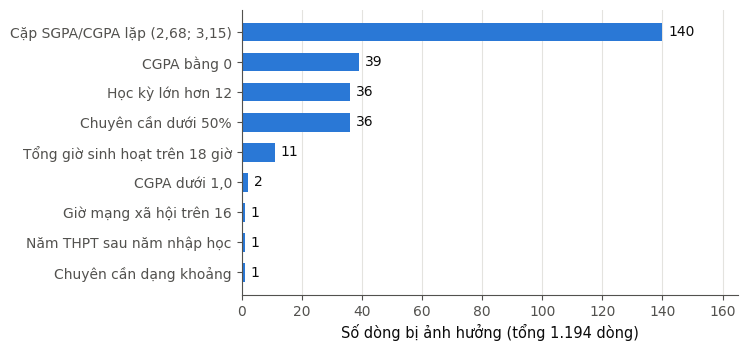

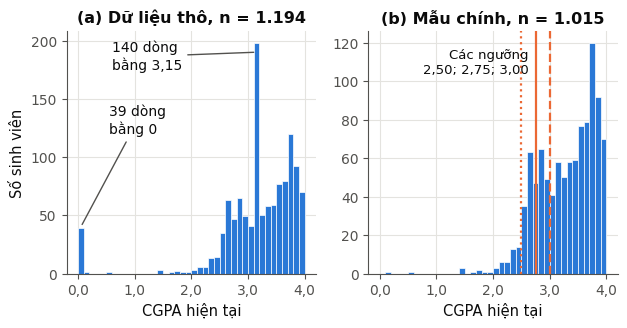

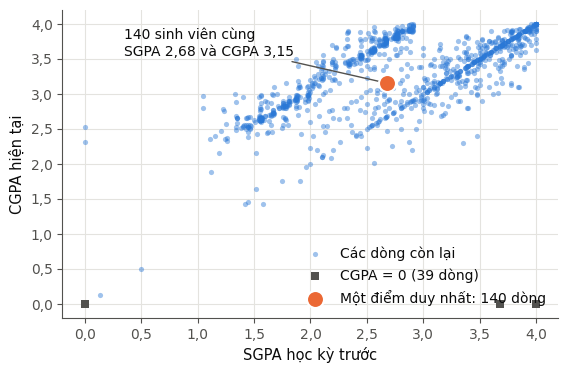

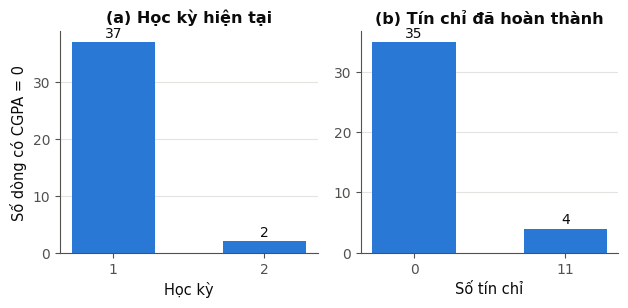

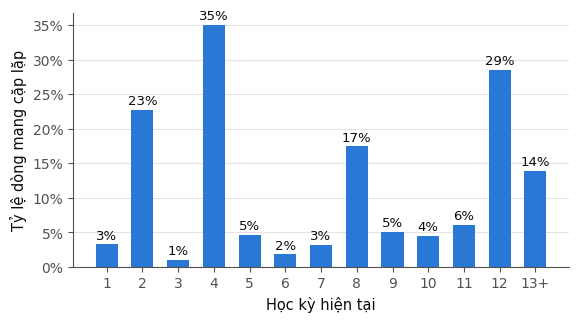

,Số dòng
"Cặp SGPA/CGPA lặp (2,68; 3,15)",140
CGPA bằng 0,39
Chuyên cần dưới 50%,36
Học kỳ lớn hơn 12,36
Tổng giờ sinh hoạt trên 18 giờ,11
Chuyên cần dạng khoảng,1
Năm THPT sau năm nhập học,1
Giờ mạng xã hội trên 16,1
"CGPA dưới 1,0",2


**t_descriptive_primary.csv**

,variable,n,mean,sd,median,q1,q3,min,max,skew
0,study_hours,1015,3.131,1.636,3.0,2.0,4.0,0.0,13.0,1.007
1,study_sessions,1015,1.943,0.851,2.0,1.0,2.0,0.0,7.0,1.021
2,attendance_pct,1015,87.712,15.915,90.0,80.0,100.0,0.0,100.0,-1.964
3,social_hours,1015,3.370,2.304,3.0,2.0,4.0,0.0,16.0,1.827
4,skill_hours,1015,2.216,1.306,2.0,1.0,3.0,0.0,12.0,1.536
5,semester_capped,1015,6.761,3.445,7.0,3.0,10.0,1.0,12.0,-0.137
6,credits_completed,1015,76.909,46.955,86.0,25.0,120.0,0.0,145.0,-0.133
7,english_level,1015,0.956,0.667,1.0,1.0,1.0,0.0,2.0,0.050


**t_placeholder_vs_rest.csv**

,variable,median_placeholder,median_other,p_mannwhitney,p_holm
0,study_hours,3.0,3.0,0.715,1.000
1,study_sessions,2.0,2.0,0.906,1.000
2,attendance_pct,90.0,90.0,0.827,1.000
3,social_hours,2.0,3.0,0.000,0.002
4,skill_hours,2.0,2.0,0.783,1.000
5,english_level,1.0,1.0,0.002,0.021
6,has_pc,1.0,1.0,0.093,0.648
7,cocurricular,0.0,0.0,0.155,0.930
8,learning_mode_online,0.0,0.0,0.425,1.000
9,uses_transport,1.0,0.0,0.005,0.038


**t_composition_shift.csv**

,variable,category,share_all_1194,share_primary_1015
0,semester_band,Học kỳ 1-4,0.376,0.327
1,semester_band,Học kỳ từ 9,0.344,0.375
2,semester_band,Học kỳ 5-8,0.280,0.298
3,cohort_band,>=2022,0.276,0.242
4,cohort_band,2021,0.275,0.290
5,cohort_band,2020,0.237,0.251
6,cohort_band,2019,0.150,0.159
7,cohort_band,<=2018,0.062,0.058


In [23]:
part_a_quality()
display(pd.Series(R["flags"], name="Số dòng").to_frame())
display(Markdown("**t_descriptive_primary.csv**"))
display(pd.read_csv(TAB / "t_descriptive_primary.csv").round(3))
display(Markdown("**t_placeholder_vs_rest.csv**"))
display(pd.read_csv(TAB / "t_placeholder_vs_rest.csv").round(3))
display(Markdown("**t_composition_shift.csv**"))
display(pd.read_csv(TAB / "t_composition_shift.csv").round(3))

### 6.4. Phần B: AQ1, phân bố CGPA và tỷ lệ nhóm cần hỗ trợ

AQ1 (Descriptive) hỏi phân bố CGPA ra sao và bao nhiêu sinh viên thuộc nhóm cần hỗ trợ ở ba ngưỡng ứng viên. Tỷ lệ được tính trên hai mẫu (mẫu chính và mẫu độ nhạy B) với khoảng tin cậy Wilson, sau đó phân tích theo khóa nhập học (kiểm định chi bình phương) và theo nhóm học kỳ (Kruskal-Wallis) để kiểm tra tính đại diện.

In [24]:
def part_b_aq1() -> None:
    rows = []
    for name, thr in [("y_lt_2_50", 2.50), ("y_lt_2_75", 2.75), ("y_lt_3_00", 3.00)]:
        for label, d in [("Mẫu chính (n = 1.015)", prim), ("Mẫu độ nhạy B (n = 1.155)", sensB)]:
            k, n = int(d[name].astype(int).sum()), len(d)
            lo, hi = wilson(k, n)
            rows.append({"threshold": thr, "sample": label, "positives": k, "n": n, "rate": k / n, "ci_low": lo, "ci_high": hi})
    t = pd.DataFrame(rows)
    t.to_csv(TAB / "t_aq1_prevalence.csv", index=False)
    R["aq1_prevalence"] = rows

    fig, ax = plt.subplots(figsize=(6.4, 3.8))
    w = 0.36
    x = np.arange(3)
    for j, (label, color) in enumerate([("Mẫu chính (n = 1.015)", BLUE), ("Mẫu độ nhạy B (n = 1.155)", BLUE_LIGHT)]):
        s = t[t["sample"] == label]
        r = s["rate"].to_numpy() * 100
        err = np.vstack([r - s["ci_low"].to_numpy() * 100, s["ci_high"].to_numpy() * 100 - r])
        bars = ax.bar(x + (j - 0.5) * w, r, w, color=color, edgecolor=BLUE if j else "none", linewidth=1, label=label, yerr=err,
                      error_kw=dict(ecolor=INK2, lw=1.2, capsize=3))
        for xi, rr, kk in zip(x + (j - 0.5) * w, r, s["positives"]):
            ax.text(xi, rr + 3.1, f"{vi(rr, 1)}%\n({kk})", ha="center", fontsize=9.5)
    ax.axhspan(10, 25, color=MID, zorder=0)
    ax.axhline(30, color=ORANGE, lw=1.4, ls="--")
    ax.set_xticks(x)
    ax.set_xticklabels(["CGPA < 2,50", "CGPA < 2,75", "CGPA < 3,00"])
    ax.set_ylabel("Tỷ lệ ca dương")
    ax.set_ylim(0, 41)
    ax.yaxis.set_major_formatter(pct_axis())
    ax.grid(axis="x", visible=False)
    h, _ = ax.get_legend_handles_labels()
    h += [plt.Rectangle((0, 0), 1, 1, fc=MID, ec="none"), plt.Line2D([0], [0], color=ORANGE, lw=1.4, ls="--")]
    ax.legend(handles=h, labels=["Mẫu chính (n = 1.015)", "Mẫu độ nhạy B (n = 1.155)",
                                 "Khoảng 10-25% theo Đề cương", "Trần gắn cờ 30%"],
              loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=9.5)
    save(fig, "fig06_target_prevalence.png")

    # Đại diện theo khóa nhập học và tỷ lệ ca dương theo khóa
    fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.5), gridspec_kw={"width_ratios": [1.15, 1]})
    yr = raw_typed["admit_year"].value_counts().sort_index()
    axes[0].bar(yr.index.astype(str), yr.values, color=BLUE, width=0.7)
    for xi, v in zip(range(len(yr)), yr.values):
        axes[0].text(xi, v + 5, str(v), ha="center", fontsize=8.8, rotation=0)
    axes[0].set_title("(a) Số sinh viên theo năm nhập học")
    axes[0].set_xlabel("Năm nhập học")
    axes[0].tick_params(axis="x", labelrotation=60)
    axes[0].grid(axis="x", visible=False)
    order = ["<=2018", "2019", "2020", "2021", ">=2022"]
    rows = []
    for k in order:
        g = prim[prim["cohort_band"] == k]
        kk, nn = int(g["y"].sum()), len(g)
        lo, hi = wilson(kk, nn)
        rows.append({"cohort": k, "n": nn, "positives": kk, "rate": kk / nn, "lo": lo, "hi": hi})
    ct = pd.DataFrame(rows)
    ct.to_csv(TAB / "t_aq1_by_cohort.csv", index=False)
    err = np.vstack([ct["rate"] - ct["lo"], ct["hi"] - ct["rate"]]) * 100
    axes[1].bar(order, ct["rate"] * 100, color=BLUE, width=0.62, yerr=err, error_kw=dict(ecolor=INK2, lw=1.2, capsize=3))
    for i, (r, n) in enumerate(zip(ct["rate"], ct["n"])):
        axes[1].text(i, r * 100 + 5.5, f"n={n}", ha="center", fontsize=8.8)
    axes[1].set_title("(b) Tỷ lệ CGPA < 2,75")
    axes[1].set_xlabel("Khóa nhập học")
    axes[1].yaxis.set_major_formatter(pct_axis())
    axes[1].set_ylim(0, 45)
    axes[1].tick_params(axis="x", labelrotation=30)
    axes[1].grid(axis="x", visible=False)
    fig.tight_layout()
    save(fig, "fig07_cohort_representativeness.png")
    R["aq1_by_cohort"] = rows
    chi = stats.chi2_contingency(pd.crosstab(prim["cohort_band"], prim["y"]))
    R["aq1_cohort_chi2"] = {"chi2": float(chi[0]), "p": float(chi[1]), "dof": int(chi[2])}

    # CGPA trung vị theo nhóm học kỳ
    by_sem = prim.groupby("semester_band")["cgpa_clean"].agg(["median", "mean", "size"]).reset_index()
    by_sem.to_csv(TAB / "t_aq1_by_semband.csv", index=False)
    R["aq1_by_semband"] = by_sem.to_dict(orient="records")
    kw = stats.kruskal(*[g["cgpa_clean"].to_numpy() for _, g in prim.groupby("semester_band")])
    R["aq1_semband_kruskal"] = {"H": float(kw[0]), "p": float(kw[1])}

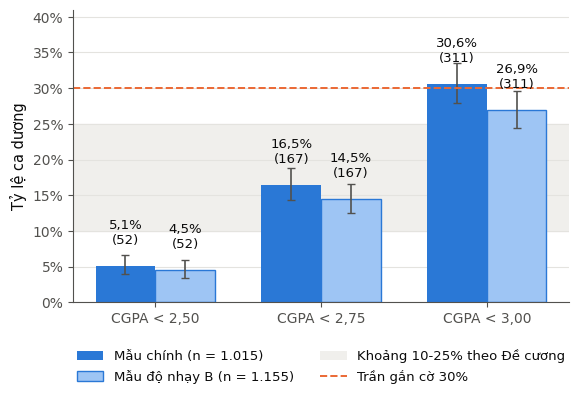

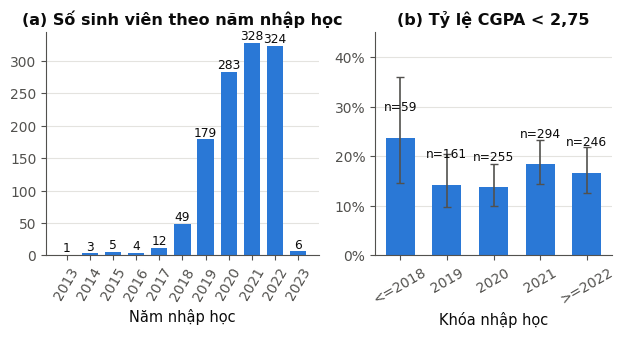

**t_aq1_prevalence.csv**

,threshold,sample,positives,n,rate,ci_low,ci_high
0,2.50,Mẫu chính (n = 1.015),52,1015,0.051,0.039,0.067
1,2.50,Mẫu độ nhạy B (n = 1.155),52,1155,0.045,0.034,0.059
2,2.75,Mẫu chính (n = 1.015),167,1015,0.165,0.143,0.189
3,2.75,Mẫu độ nhạy B (n = 1.155),167,1155,0.145,0.125,0.166
4,3.00,Mẫu chính (n = 1.015),311,1015,0.306,0.279,0.335
5,3.00,Mẫu độ nhạy B (n = 1.155),311,1155,0.269,0.244,0.296


**t_aq1_by_cohort.csv**

,cohort,n,positives,rate,lo,hi
0,<=2018,59,14,0.237,0.147,0.360
1,2019,161,23,0.143,0.097,0.205
2,2020,255,35,0.137,0.100,0.185
3,2021,294,54,0.184,0.144,0.232
4,>=2022,246,41,0.167,0.125,0.218


**t_aq1_by_semband.csv**

,semester_band,median,mean,size
0,Học kỳ 1-4,3.460,3.332,332
1,Học kỳ 5-8,3.345,3.255,302
2,Học kỳ từ 9,3.380,3.280,381


In [25]:
part_b_aq1()
display(Markdown("**t_aq1_prevalence.csv**"))
display(pd.read_csv(TAB / "t_aq1_prevalence.csv").round(3))
display(Markdown("**t_aq1_by_cohort.csv**"))
display(pd.read_csv(TAB / "t_aq1_by_cohort.csv").round(3))
display(Markdown("**t_aq1_by_semband.csv**"))
display(pd.read_csv(TAB / "t_aq1_by_semband.csv").round(3))

### 6.5. Phần C: AQ2, thói quen học tập

AQ2 (Diagnostic) hỏi năm biến thói quen khác biệt thế nào giữa nhóm cần hỗ trợ và nhóm còn lại. Với mỗi biến, notebook tính trung vị và khoảng tứ phân vị theo nhóm, PS kèm khoảng tin cậy bootstrap, p của Mann-Whitney hiệu chỉnh Holm và tương quan Spearman với CGPA. Chuyên cần được phân tích sâu hơn: tỷ lệ cần hỗ trợ theo dải chuyên cần (kiểm tra xu hướng), phân tầng theo nhóm học kỳ để loại trừ nhiễu, và ma trận chuyên cần × giờ học để phát hiện quan hệ phi tuyến hoặc tương tác.

In [26]:
def part_c_aq2() -> None:
    d1 = prim[prim["y"] == 1]
    d0 = prim[prim["y"] == 0]
    rows = []
    for v in CORE_AQ2:
        x1, x0 = d1[v].dropna().to_numpy(float), d0[v].dropna().to_numpy(float)
        ps = prob_superiority(x1, x0)
        lo, hi = ps_bootstrap_ci(x1, x0)
        p = float(stats.mannwhitneyu(x1, x0, alternative="two-sided")[1])
        rho, pr = stats.spearmanr(prim[v], prim["cgpa_clean"])
        rows.append({"variable": v, "median_support": float(np.median(x1)), "q1_support": float(np.percentile(x1, 25)),
                     "q3_support": float(np.percentile(x1, 75)), "median_rest": float(np.median(x0)),
                     "q1_rest": float(np.percentile(x0, 25)), "q3_rest": float(np.percentile(x0, 75)),
                     "ps": ps, "ps_lo": lo, "ps_hi": hi, "p": p, "spearman_rho": float(rho), "spearman_p": float(pr)})
    t = pd.DataFrame(rows)
    t["p_holm"] = holm(t["p"].tolist())
    t.to_csv(TAB / "t_aq2_numeric.csv", index=False)
    R["aq2"] = t.to_dict(orient="records")

    # Hình box theo nhóm
    fig, axes = plt.subplots(1, 5, figsize=(6.4, 3.6))
    for ax, v in zip(axes, CORE_AQ2):
        bp = ax.boxplot([d1[v].dropna(), d0[v].dropna()], widths=0.62, patch_artist=True, showfliers=True,
                        medianprops=dict(color=INK, lw=1.6), flierprops=dict(marker="o", markersize=2.5, markerfacecolor=INK2, markeredgewidth=0, alpha=.5),
                        whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
        for patch, c in zip(bp["boxes"], [ORANGE, BLUE]):
            patch.set_facecolor(c)
            patch.set_alpha(0.85)
            patch.set_edgecolor(INK2)
        row = t[t["variable"] == v].iloc[0]
        wrap = {"study_hours": "Giờ học", "study_sessions": "Số lần\nngồi học", "attendance_pct": "Chuyên cần",
                "social_hours": "Giờ dùng\nmạng xã hội", "skill_hours": "Giờ phát\ntriển kỹ năng"}
        ax.set_title(wrap.get(v, LABELS[v]), fontsize=9.3, pad=6)
        ax.set_xticks([1, 2])
        ax.set_xticklabels(["A", "B"])
        ax.set_xlabel(f"PS={vi(row['ps'], 2)}", fontsize=9.2)
        ax.grid(axis="x", visible=False)
        ax.tick_params(axis="y", labelsize=9)
    axes[0].set_ylabel("Giá trị khai báo")
    fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=ORANGE, ec=INK2), plt.Rectangle((0, 0), 1, 1, fc=BLUE, ec=INK2)],
               labels=["A: " + G_SUPPORT, "B: " + G_REST], loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.06))
    fig.tight_layout()
    save(fig, "fig08_aq2_distributions.png")

    # Chuyên cần theo dải và phân tầng theo nhóm học kỳ
    bins = [-1, 69.99, 79.99, 89.99, 94.99, 100]
    labs = ["< 70", "70-79", "80-89", "90-94", "95-100"]
    prim["att_bin"] = pd.cut(prim["attendance_pct"], bins=bins, labels=labs)
    rows = []
    for k in labs:
        g = prim[prim["att_bin"] == k]
        kk, nn = int(g["y"].sum()), len(g)
        lo, hi = wilson(kk, nn)
        rows.append({"att_bin": k, "n": nn, "positives": kk, "rate": kk / nn, "lo": lo, "hi": hi})
    ab = pd.DataFrame(rows)
    ab.to_csv(TAB / "t_aq2_attendance_bins.csv", index=False)
    R["aq2_att_bins"] = rows
    trend = stats.spearmanr(prim["attendance_pct"], prim["y"])
    R["aq2_att_trend"] = {"rho": float(trend[0]), "p": float(trend[1])}

    fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.5), gridspec_kw={"width_ratios": [1, 1.05]})
    err = np.vstack([ab["rate"] - ab["lo"], ab["hi"] - ab["rate"]]) * 100
    axes[0].bar(labs, ab["rate"] * 100, color=BLUE, width=0.64, yerr=err, error_kw=dict(ecolor=INK2, lw=1.2, capsize=3))
    for i, (r, n) in enumerate(zip(ab["rate"], ab["n"])):
        axes[0].text(i, r * 100 + 6.2, f"n={n}", ha="center", fontsize=8.8)
    axes[0].set_title("(a) Tỷ lệ CGPA < 2,75")
    axes[0].set_xlabel("Chuyên cần (%)")
    axes[0].yaxis.set_major_formatter(pct_axis())
    axes[0].set_ylim(0, 62)
    axes[0].tick_params(axis="x", labelsize=9)
    axes[0].grid(axis="x", visible=False)
    strat_rows = []
    sem_order = ["Học kỳ 1-4", "Học kỳ 5-8", "Học kỳ từ 9"]
    markers = ["o", "s", "D"]
    cols = [BLUE_LIGHT, BLUE, BLUE_DARK]
    for (sb, mk, cl) in zip(sem_order, markers, cols):
        g = prim[prim["semester_band"] == sb]
        rr = []
        for k in labs:
            gg = g[g["att_bin"] == k]
            rr.append(gg["y"].mean() * 100 if len(gg) >= 10 else np.nan)
            strat_rows.append({"semester_band": sb, "att_bin": k, "n": len(gg), "positives": int(gg["y"].sum()),
                               "rate": gg["y"].mean() if len(gg) else np.nan})
        axes[1].plot(labs, rr, marker=mk, color=cl, lw=2, markersize=6.5, label=sb, markeredgecolor="white")
    pd.DataFrame(strat_rows).to_csv(TAB / "t_aq2_attendance_by_semband.csv", index=False)
    axes[1].set_title("(b) Phân tầng theo học kỳ")
    axes[1].set_xlabel("Chuyên cần (%)")
    axes[1].yaxis.set_major_formatter(pct_axis())
    axes[1].tick_params(axis="x", labelsize=9)
    axes[1].legend(frameon=False, fontsize=9, loc="upper right")
    axes[1].grid(axis="x", visible=False)
    fig.tight_layout()
    save(fig, "fig10_aq2_attendance_deepdive.png")
    strat_ps = {}
    for sb in sem_order:
        g = prim[prim["semester_band"] == sb]
        a, b = g.loc[g["y"] == 1, "attendance_pct"].to_numpy(float), g.loc[g["y"] == 0, "attendance_pct"].to_numpy(float)
        strat_ps[sb] = {"n": int(len(g)), "pos": int(len(a)), "ps": prob_superiority(a, b), "p": float(stats.mannwhitneyu(a, b)[1])}
    R["aq2_attendance_strat"] = strat_ps

    # Giờ học theo nhóm kết hợp: ma trận chuyên cần x giờ học (phi tuyến, tương tác)
    prim["study_bin"] = pd.cut(prim["study_hours"], bins=[-1, 1, 2, 3, 4, 20], labels=["0-1", "2", "3", "4", "5+"])
    prim["att_bin2"] = pd.cut(prim["attendance_pct"], bins=[-1, 79.99, 89.99, 100], labels=["< 80", "80-89", "90-100"])
    mat = prim.pivot_table(index="att_bin2", columns="study_bin", values="y", aggfunc="mean", observed=False) * 100
    cnt = prim.pivot_table(index="att_bin2", columns="study_bin", values="y", aggfunc="size", observed=False)
    mat.to_csv(TAB / "t_aq2_att_study_matrix.csv")
    cnt.to_csv(TAB / "t_aq2_att_study_counts.csv")
    R["aq2_matrix"] = {"rate": mat.round(1).to_dict(), "n": cnt.to_dict()}

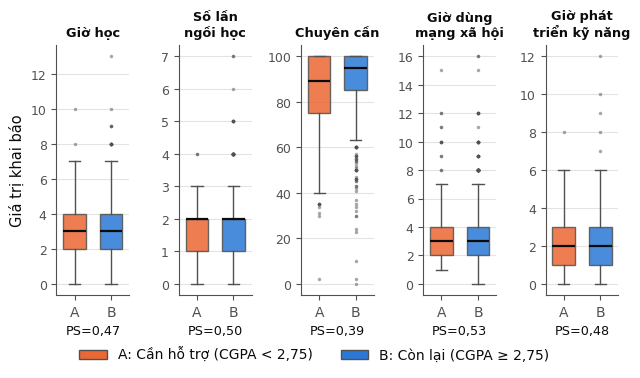

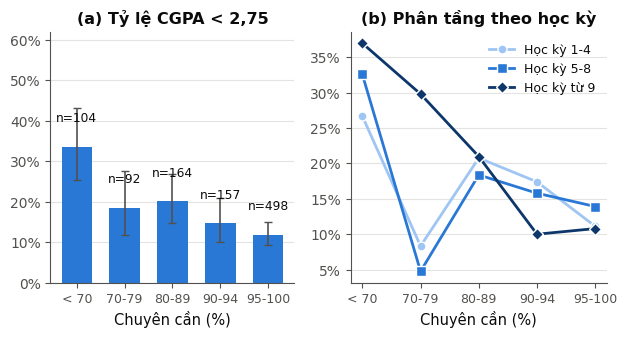

**t_aq2_numeric.csv**

,variable,median_support,q1_support,q3_support,median_rest,q1_rest,q3_rest,ps,ps_lo,ps_hi,p,spearman_rho,spearman_p,p_holm
0,study_hours,3.0,2.0,4.0,3.0,2.0,4.0,0.470,0.426,0.516,0.204,0.043,0.169,0.675
1,study_sessions,2.0,1.0,2.0,2.0,1.0,2.0,0.502,0.457,0.546,0.924,0.038,0.229,0.924
2,attendance_pct,89.0,75.0,100.0,95.0,85.0,100.0,0.395,0.347,0.442,0.000,0.264,0.000,0.000
3,social_hours,3.0,2.0,4.0,3.0,2.0,4.0,0.533,0.488,0.577,0.169,-0.115,0.000,0.675
4,skill_hours,2.0,1.0,3.0,2.0,1.0,3.0,0.480,0.431,0.528,0.393,0.023,0.461,0.787


**t_aq2_attendance_bins.csv**

,att_bin,n,positives,rate,lo,hi
0,< 70,104,35,0.337,0.253,0.432
1,70-79,92,17,0.185,0.119,0.276
2,80-89,164,33,0.201,0.147,0.269
3,90-94,157,23,0.146,0.100,0.210
4,95-100,498,59,0.118,0.093,0.150


**t_aq2_attendance_by_semband.csv**

,semester_band,att_bin,n,positives,rate
0,Học kỳ 1-4,< 70,15,4,0.267
1,Học kỳ 1-4,70-79,24,2,0.083
2,Học kỳ 1-4,80-89,53,11,0.208
3,Học kỳ 1-4,90-94,69,12,0.174
4,Học kỳ 1-4,95-100,171,19,0.111
5,Học kỳ 5-8,< 70,43,14,0.326
6,Học kỳ 5-8,70-79,21,1,0.048
7,Học kỳ 5-8,80-89,49,9,0.184
8,Học kỳ 5-8,90-94,38,6,0.158
9,Học kỳ 5-8,95-100,151,21,0.139


**t_aq2_att_study_matrix.csv**

,att_bin2,0-1,2,3,4,5+
0,< 80,21.622,31.667,21.154,23.529,33.333
1,80-89,17.857,17.647,26.471,20.690,18.182
2,90-100,12.500,14.557,14.689,11.215,8.511


In [27]:
part_c_aq2()
display(Markdown("**t_aq2_numeric.csv**"))
display(pd.read_csv(TAB / "t_aq2_numeric.csv").round(3))
display(Markdown("**t_aq2_attendance_bins.csv**"))
display(pd.read_csv(TAB / "t_aq2_attendance_bins.csv").round(3))
display(Markdown("**t_aq2_attendance_by_semband.csv**"))
display(pd.read_csv(TAB / "t_aq2_attendance_by_semband.csv").round(3))
display(Markdown("**t_aq2_att_study_matrix.csv**"))
display(pd.read_csv(TAB / "t_aq2_att_study_matrix.csv").round(3))

### 6.6. Phần D: AQ3, điều kiện và bối cảnh học tập

AQ3 (Diagnostic) hỏi điều kiện và bối cảnh học tập liên hệ ra sao với nhãn. Biến số và thứ bậc dùng PS như AQ2; biến nhị phân dùng tỷ lệ theo nhóm, OR thô và OR hiệu chỉnh theo nhóm học kỳ (Mantel-Haenszel). Trình độ tiếng Anh được so sánh từng mức với mức Intermediate vì quan hệ không đơn điệu, kèm kiểm định chi bình phương và Cramér's V. Ma trận tương quan Spearman giữa các biến lõi được dùng để phát hiện đa cộng tuyến, đặc biệt giữa học kỳ và số tín chỉ.

In [28]:
def part_d_aq3() -> None:
    d1 = prim[prim["y"] == 1]
    d0 = prim[prim["y"] == 0]
    rows = []
    for v in ["english_level", "semester_capped", "credits_completed", "credits_per_semester"]:
        x1, x0 = d1[v].dropna().to_numpy(float), d0[v].dropna().to_numpy(float)
        ps = prob_superiority(x1, x0)
        lo, hi = ps_bootstrap_ci(x1, x0)
        p = float(stats.mannwhitneyu(x1, x0)[1])
        rho, pr = stats.spearmanr(prim[v], prim["cgpa_clean"], nan_policy="omit")
        rows.append({"variable": v, "median_support": float(np.median(x1)), "median_rest": float(np.median(x0)),
                     "ps": ps, "ps_lo": lo, "ps_hi": hi, "p": p, "spearman_rho": float(rho), "spearman_p": float(pr)})
    tn = pd.DataFrame(rows)
    tn["p_holm"] = holm(tn["p"].tolist())

    # Biến nhị phân: tỷ lệ, OR thô, OR hiệu chỉnh theo nhóm học kỳ
    bin_rows = []
    for v in ["learning_mode_online", "has_pc", "uses_transport", "cocurricular", "has_smartphone"]:
        a = int(((prim[v] == 1) & (prim["y"] == 1)).sum())
        b = int(((prim[v] == 1) & (prim["y"] == 0)).sum())
        c = int(((prim[v] == 0) & (prim["y"] == 1)).sum())
        d = int(((prim[v] == 0) & (prim["y"] == 0)).sum())
        orr, lo, hi = odds_ratio(a, b, c, d)
        mh, mlo, mhi = mantel_haenszel(prim, v, "y", "semester_band")
        p = float(stats.fisher_exact([[a, b], [c, d]])[1])
        bin_rows.append({"variable": v, "n_yes": a + b, "rate_yes": a / (a + b), "n_no": c + d, "rate_no": c / (c + d),
                         "or_crude": orr, "or_lo": lo, "or_hi": hi, "or_mh": mh, "mh_lo": mlo, "mh_hi": mhi,
                         "p_fisher": p, "cramers_v": cramers_v(np.array([[a, b], [c, d]]))})
    # Tiếng Anh: đối chiếu từng mức với Intermediate (quan hệ không đơn điệu)
    for name, lvl in [("english_basic_vs_inter", 0), ("english_adv_vs_inter", 2)]:
        sub = prim[prim["english_level"].isin([1, lvl])].copy()
        sub["exp"] = (sub["english_level"] == lvl).astype(int)
        a = int(((sub["exp"] == 1) & (sub["y"] == 1)).sum()); b = int(((sub["exp"] == 1) & (sub["y"] == 0)).sum())
        c = int(((sub["exp"] == 0) & (sub["y"] == 1)).sum()); d = int(((sub["exp"] == 0) & (sub["y"] == 0)).sum())
        orr, lo, hi = odds_ratio(a, b, c, d)
        mh, mlo, mhi = mantel_haenszel(sub, "exp", "y", "semester_band")
        bin_rows.append({"variable": name, "n_yes": a + b, "rate_yes": a / (a + b), "n_no": c + d, "rate_no": c / (c + d),
                         "or_crude": orr, "or_lo": lo, "or_hi": hi, "or_mh": mh, "mh_lo": mlo, "mh_hi": mhi,
                         "p_fisher": float(stats.fisher_exact([[a, b], [c, d]])[1]),
                         "cramers_v": cramers_v(np.array([[a, b], [c, d]]))})
    tb = pd.DataFrame(bin_rows)
    main_family = tb["variable"] != "has_smartphone"
    tb["p_holm"] = np.nan
    tb.loc[main_family, "p_holm"] = holm(tb.loc[main_family, "p_fisher"].tolist())
    tn.to_csv(TAB / "t_aq3_numeric.csv", index=False)
    tb.to_csv(TAB / "t_aq3_binary.csv", index=False)
    R["aq3_numeric"] = tn.to_dict(orient="records")
    R["aq3_binary"] = tb.to_dict(orient="records")
    ct = pd.crosstab(prim["english_level"], prim["y"])
    R["aq3_english"] = {"chi2_p": float(stats.chi2_contingency(ct)[1]), "v": cramers_v(ct.to_numpy()),
                        "rates": (ct[1] / ct.sum(axis=1)).to_dict(), "n": ct.sum(axis=1).to_dict()}
    ctb = pd.crosstab(prim["semester_band"], prim["y"])
    R["aq3_semband"] = {"chi2_p": float(stats.chi2_contingency(ctb)[1]), "v": cramers_v(ctb.to_numpy()),
                        "rates": (ctb[1] / ctb.sum(axis=1)).to_dict(), "n": ctb.sum(axis=1).to_dict()}

    # Hình 11: tỷ lệ ca dương theo hạng mục (2 x 4)
    panels = [("learning_mode_online", ["Offline", "Online"], "Hình thức\nhọc ưa thích"),
              ("has_pc", ["Không", "Có"], "Máy tính\ncá nhân"),
              ("uses_transport", ["Không", "Có"], "Xe đưa đón\ncủa trường"),
              ("cocurricular", ["Không", "Có"], "Hoạt động\nngoại khóa"),
              ("english_level", ["Cơ bản", "Trung bình", "Nâng cao"], "Trình độ\ntiếng Anh"),
              ("semester_band", ["Học kỳ 1-4", "Học kỳ 5-8", "Học kỳ từ 9"], "Nhóm\nhọc kỳ"),
              ("has_smartphone", ["Không", "Có"], "Điện thoại\nthông minh"),
              ("consultancy_bin", ["Không", "Có"], "Đã tham gia\ntư vấn")]
    fig, axes = plt.subplots(2, 4, figsize=(6.4, 5.0), sharey=True)
    for ax, (v, cats, title) in zip(axes.ravel(), panels):
        keys = cats if v == "semester_band" else list(range(len(cats)))
        rr, los, his, ns = [], [], [], []
        for k in keys:
            g = prim[prim[v] == k]
            kk, nn = int(g["y"].sum()), len(g)
            lo, hi = wilson(kk, nn)
            rr.append(kk / nn * 100); los.append(lo * 100); his.append(hi * 100); ns.append(nn)
        err = np.vstack([np.array(rr) - np.array(los), np.array(his) - np.array(rr)])
        color = INK2 if v in ("consultancy_bin", "has_smartphone") else BLUE
        ax.bar(range(len(cats)), rr, color=color, width=0.62, yerr=err, error_kw=dict(ecolor=INK, lw=1.1, capsize=2.5))
        for i, (r, n, h) in enumerate(zip(rr, ns, his)):
            ax.text(i, h + 1.0, f"n={n}", ha="center", fontsize=7.6, rotation=90, va="bottom")
        ax.set_title(title, fontsize=8.8, pad=5)
        ax.set_xticks(range(len(cats)))
        ax.set_xticklabels([c.replace("Học kỳ ", "HK ").replace("Trung bình", "T.bình").replace("Nâng cao", "N.cao") for c in cats], fontsize=8.2, rotation=0)
        ax.set_ylim(0, 62)
        ax.grid(axis="x", visible=False)
        ax.yaxis.set_major_formatter(pct_axis())
        ax.tick_params(axis="y", labelsize=8.8)
    for ax in axes[:, 1:].ravel():
        ax.tick_params(axis="y", labelleft=False)
    axes[0, 0].set_ylabel("Tỷ lệ CGPA < 2,75")
    axes[1, 0].set_ylabel("Tỷ lệ CGPA < 2,75")
    fig.tight_layout(h_pad=1.6)
    save(fig, "fig11_aq3_categorical.png")

    # Hình 9: forest PS cho AQ2 và AQ3 (biến số/thứ bậc)
    ta2 = pd.DataFrame(R["aq2"])
    fr = pd.concat([ta2[["variable", "ps", "ps_lo", "ps_hi", "p_holm"]].assign(group="AQ2"),
                    tn[["variable", "ps", "ps_lo", "ps_hi", "p_holm"]].assign(group="AQ3")], ignore_index=True)
    fr.to_csv(TAB / "t_forest_ps.csv", index=False)
    fig, ax = plt.subplots(figsize=(6.4, 3.9))
    y = np.arange(len(fr))[::-1]
    for yi, row in zip(y, fr.itertuples()):
        c = BLUE if row.group == "AQ2" else BLUE_DARK
        ax.plot([row.ps_lo, row.ps_hi], [yi, yi], color=c, lw=2)
        ax.scatter([row.ps], [yi], color=c, s=55, zorder=5, marker="o" if row.group == "AQ2" else "D", edgecolor="white", linewidths=1)
        sig = "*" if row.p_holm < 0.05 else ""
        ax.text(0.745, yi, f"{vi(row.ps, 2)}{sig}", va="center", fontsize=9.8)
    ax.axvline(0.5, color=ORANGE, lw=1.4, ls="--")
    ax.set_yticks(y)
    ax.set_yticklabels([LABELS[v] for v in fr["variable"]], fontsize=9.6)
    ax.set_xlim(0.30, 0.80)
    ax.set_xlabel("Xác suất ưu thế PS (0,5 = không khác biệt; nhỏ hơn 0,5 = nhóm cần hỗ trợ có giá trị thấp hơn)", fontsize=8.6)
    ax.xaxis.set_major_formatter(vi_axis(1))
    ax.grid(axis="y", visible=False)
    ax.legend(handles=[plt.Line2D([0], [0], marker="o", color=BLUE, lw=2, label="AQ2: thói quen học tập"),
                       plt.Line2D([0], [0], marker="D", color=BLUE_DARK, lw=2, label="AQ3: điều kiện và bối cảnh")],
              loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False, fontsize=9.2)
    save(fig, "fig09_forest_probability_of_superiority.png")

    # Hình 12: OR thô và OR hiệu chỉnh
    ob = tb[tb["variable"].isin(["learning_mode_online", "has_pc", "uses_transport", "cocurricular",
                                  "english_basic_vs_inter", "english_adv_vs_inter"])].copy()
    names = {"learning_mode_online": "Ưa thích học trực tuyến", "has_pc": "Có máy tính cá nhân",
             "uses_transport": "Dùng xe đưa đón", "cocurricular": "Hoạt động ngoại khóa",
             "english_basic_vs_inter": "Tiếng Anh Cơ bản (so với T.bình)",
             "english_adv_vs_inter": "Tiếng Anh Nâng cao (so với T.bình)"}
    fig, ax = plt.subplots(figsize=(6.4, 3.7))
    y = np.arange(len(ob))[::-1]
    for yi, row in zip(y, ob.itertuples()):
        ax.plot([row.or_lo, row.or_hi], [yi + 0.14, yi + 0.14], color=BLUE, lw=2)
        ax.scatter([row.or_crude], [yi + 0.14], color=BLUE, s=48, zorder=5, edgecolor="white", linewidths=1)
        ax.plot([row.mh_lo, row.mh_hi], [yi - 0.14, yi - 0.14], color=BLUE_DARK, lw=2)
        ax.scatter([row.or_mh], [yi - 0.14], color=BLUE_DARK, s=48, zorder=5, marker="D", edgecolor="white", linewidths=1)
    ax.axvline(1, color=ORANGE, lw=1.4, ls="--")
    ax.set_xscale("log")
    ax.set_xlim(0.4, 3.8)
    ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3])
    ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax.get_xaxis().set_major_formatter(FuncFormatter(lambda v, _: vi(v, 2).rstrip("0").rstrip(",") if v != 1 else "1"))
    ax.set_yticks(y)
    ax.set_yticklabels([names[v] for v in ob["variable"]])
    ax.set_xlabel("Tỷ số chênh (OR) của CGPA < 2,75, thang logarit")
    ax.grid(axis="y", visible=False)
    ax.legend(handles=[plt.Line2D([0], [0], marker="o", color=BLUE, lw=2, label="OR thô"),
                       plt.Line2D([0], [0], marker="D", color=BLUE_DARK, lw=2, label="OR hiệu chỉnh theo nhóm học kỳ (Mantel-Haenszel)")],
              loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=1, frameon=False, fontsize=9)
    save(fig, "fig12_aq3_odds_ratios.png")

    # Hình 13: tương quan Spearman
    cols = ["cgpa_clean"] + CORE_FEATURES[:0] + CORE_AQ2 + ["english_level", "semester_capped", "credits_completed", "credits_per_semester",
                                                                  "learning_mode_online", "has_pc", "uses_transport", "cocurricular"]
    cols = list(dict.fromkeys(cols))
    cm = prim[cols].astype(float).corr(method="spearman")
    short = {"cgpa_clean": "CGPA", "study_hours": "Giờ học", "study_sessions": "Lần học", "attendance_pct": "Chuyên cần",
             "social_hours": "Mạng XH", "skill_hours": "Kỹ năng", "english_level": "Tiếng Anh", "semester_capped": "Học kỳ",
             "credits_completed": "Tín chỉ", "credits_per_semester": "Tín chỉ/HK", "learning_mode_online": "Học online",
             "has_pc": "Có PC", "uses_transport": "Xe đưa đón", "cocurricular": "Ngoại khóa"}
    from matplotlib.colors import LinearSegmentedColormap
    cmap = LinearSegmentedColormap.from_list("div", [ORANGE, MID, BLUE])
    fig, ax = plt.subplots(figsize=(6.4, 5.6))
    im = ax.imshow(cm.to_numpy(), cmap=cmap, vmin=-1, vmax=1)
    ax.set_xticks(range(len(cols)))
    ax.set_yticks(range(len(cols)))
    ax.set_xticklabels([short[c] for c in cols], rotation=50, ha="right", fontsize=9.3)
    ax.set_yticklabels([short[c] for c in cols], fontsize=9.3)
    for i in range(len(cols)):
        for j in range(len(cols)):
            v = cm.to_numpy()[i, j]
            if i != j and abs(v) >= 0.15:
                ax.text(j, i, vi(v, 2), ha="center", va="center", fontsize=7.4, color=INK)
    ax.grid(False)
    cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
    cb.ax.tick_params(labelsize=9)
    cb.outline.set_visible(False)
    save(fig, "fig13_spearman_heatmap.png")
    cm.to_csv(TAB / "t_spearman_matrix.csv")
    R["spearman_cgpa"] = cm["cgpa_clean"].drop("cgpa_clean").round(3).to_dict()
    R["spearman_pairs_strong"] = [
        {"a": a, "b": b, "rho": float(cm.loc[a, b])} for i, a in enumerate(cols) for b in cols[i + 1:] if abs(cm.loc[a, b]) >= 0.5 and a != "cgpa_clean"]

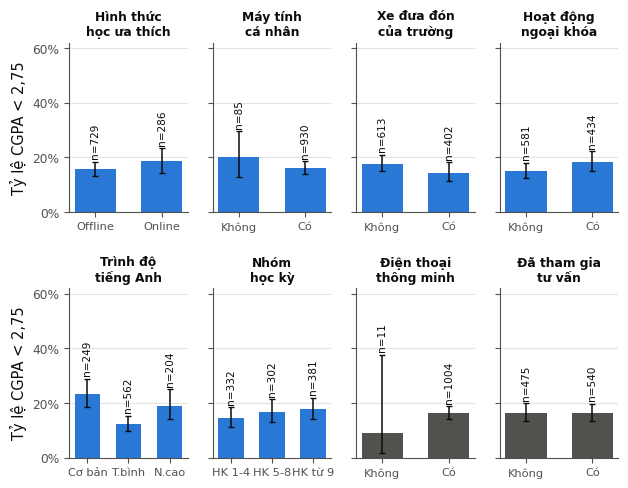

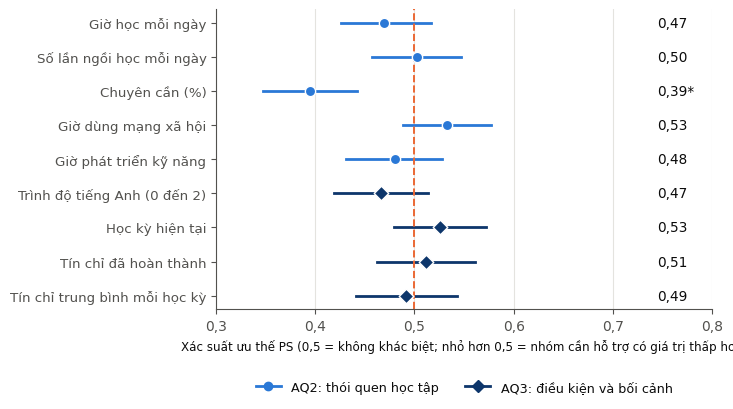

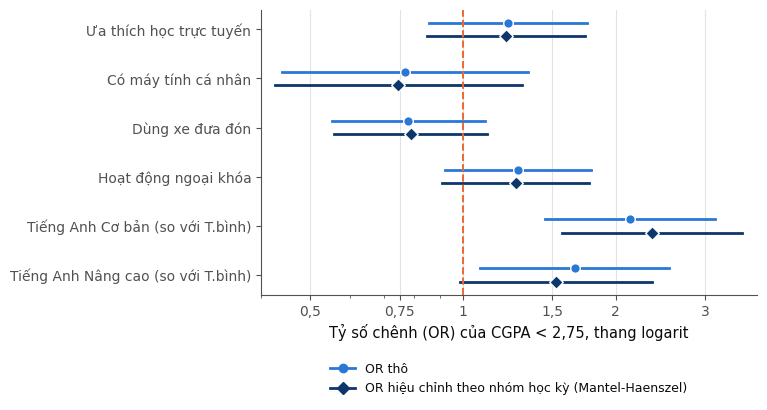

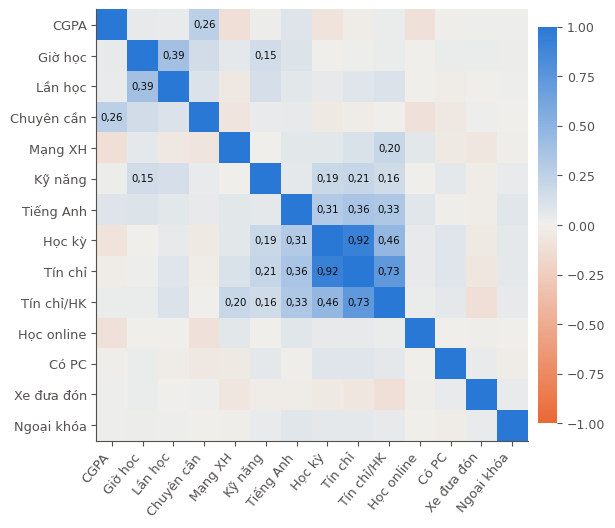

**t_aq3_numeric.csv**

,variable,median_support,median_rest,ps,ps_lo,ps_hi,p,spearman_rho,spearman_p,p_holm
0,english_level,1.000,1.0,0.466,0.418,0.513,0.121,0.091,0.004,0.484
1,semester_capped,7.000,7.0,0.526,0.479,0.572,0.286,-0.083,0.008,0.859
2,credits_completed,86.000,86.0,0.511,0.462,0.561,0.645,-0.029,0.352,1.000
3,credits_per_semester,10.875,11.0,0.492,0.441,0.543,0.741,0.024,0.443,1.000


**t_aq3_binary.csv**

,variable,n_yes,rate_yes,n_no,rate_no,or_crude,or_lo,or_hi,or_mh,mh_lo,mh_hi,p_fisher,cramers_v,p_holm
0,learning_mode_online,286,0.185,729,0.156,1.227,0.857,1.757,1.217,0.850,1.743,0.261,0.035,0.586
1,has_pc,930,0.161,85,0.200,0.769,0.440,1.346,0.746,0.425,1.308,0.360,0.029,0.586
2,uses_transport,402,0.144,613,0.178,0.780,0.551,1.103,0.789,0.557,1.117,0.167,0.044,0.586
3,cocurricular,434,0.184,581,0.150,1.283,0.920,1.790,1.270,0.909,1.773,0.147,0.046,0.586
4,has_smartphone,1004,0.165,11,0.091,1.981,0.252,15.579,1.995,0.252,15.801,1.000,0.021,NaN
5,english_basic_vs_inter,249,0.233,562,0.125,2.134,1.451,3.140,2.361,1.570,3.549,0.000,0.137,0.001
6,english_adv_vs_inter,204,0.191,562,0.125,1.661,1.081,2.553,1.528,0.988,2.362,0.026,0.084,0.129


**t_forest_ps.csv**

,variable,ps,ps_lo,ps_hi,p_holm,group
0,study_hours,0.470,0.426,0.516,0.675,AQ2
1,study_sessions,0.502,0.457,0.546,0.924,AQ2
2,attendance_pct,0.395,0.347,0.442,0.000,AQ2
3,social_hours,0.533,0.488,0.577,0.675,AQ2
4,skill_hours,0.480,0.431,0.528,0.787,AQ2
5,english_level,0.466,0.418,0.513,0.484,AQ3
6,semester_capped,0.526,0.479,0.572,0.859,AQ3
7,credits_completed,0.511,0.462,0.561,1.000,AQ3
8,credits_per_semester,0.492,0.441,0.543,1.000,AQ3


In [29]:
part_d_aq3()
display(Markdown("**t_aq3_numeric.csv**"))
display(pd.read_csv(TAB / "t_aq3_numeric.csv").round(3))
display(Markdown("**t_aq3_binary.csv**"))
display(pd.read_csv(TAB / "t_aq3_binary.csv").round(3))
display(Markdown("**t_forest_ps.csv**"))
display(pd.read_csv(TAB / "t_forest_ps.csv").round(3))

### 6.7. Phần E: bằng chứng rò rỉ dữ liệu

Phần E định lượng lý do loại các biến rò rỉ khỏi tập đặc trưng. Cảnh cáo học vụ, đình chỉ, học bổng thành tích và việc đã tham gia tư vấn đều là hệ quả (hoặc có quan hệ ngược chiều) của kết quả học tập, nên có liên hệ rất mạnh với nhãn. SGPA kỳ trước là một thành phần cấu thành CGPA. Nếu đưa các biến này vào mô hình, hiệu năng đánh giá sẽ cao giả tạo và không phản ánh giá trị sàng lọc của phiếu khảo sát.

In [30]:
def part_e_leakage() -> None:
    rows = []
    for v, lab in [("probation_bin", "Từng bị cảnh cáo học vụ"), ("suspension_bin", "Từng bị đình chỉ"),
                   ("scholarship_bin", "Có học bổng thành tích"), ("consultancy_bin", "Đã tham gia tư vấn")]:
        a = int(((prim[v] == 1) & (prim["y"] == 1)).sum()); b = int(((prim[v] == 1) & (prim["y"] == 0)).sum())
        c = int(((prim[v] == 0) & (prim["y"] == 1)).sum()); d = int(((prim[v] == 0) & (prim["y"] == 0)).sum())
        orr, lo, hi = odds_ratio(a, b, c, d)
        rows.append({"variable": v, "label": lab, "n_yes": a + b, "rate_yes": a / (a + b), "rate_no": c / (c + d),
                     "or": orr, "or_lo": lo, "or_hi": hi, "p": float(stats.fisher_exact([[a, b], [c, d]])[1])})
    tl = pd.DataFrame(rows)
    tl.to_csv(TAB / "t_leakage_evidence.csv", index=False)
    s = prim[prim["prev_sgpa_clean"].notna()]
    rho, p = stats.spearmanr(s["prev_sgpa_clean"], s["cgpa_clean"])
    ps = prob_superiority(s.loc[s["y"] == 1, "prev_sgpa_clean"].to_numpy(float), s.loc[s["y"] == 0, "prev_sgpa_clean"].to_numpy(float))
    R["leakage"] = {"rows": rows, "sgpa_rho": float(rho), "sgpa_p": float(p), "sgpa_ps": ps, "sgpa_n": int(len(s))}

    fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.5), gridspec_kw={"width_ratios": [1.05, 1]})
    axes[0].scatter(s["prev_sgpa_clean"], s["cgpa_clean"], s=11, color=BLUE, alpha=0.4, linewidths=0)
    axes[0].set_xlabel("SGPA học kỳ trước")
    axes[0].set_ylabel("CGPA hiện tại")
    axes[0].set_title(f"(a) Spearman ρ = {vi(rho, 2)}")
    axes[0].xaxis.set_major_formatter(vi_axis(1))
    axes[0].yaxis.set_major_formatter(vi_axis(1))
    labs = [r["label"].replace("Từng bị ", "").replace("Có ", "").replace("Đã ", "") for r in rows]
    yy = np.arange(len(rows))[::-1]
    for yi, r in zip(yy, rows):
        axes[1].barh(yi + 0.17, r["rate_yes"] * 100, 0.32, color=ORANGE)
        axes[1].barh(yi - 0.17, r["rate_no"] * 100, 0.32, color=BLUE)
        axes[1].text(r["rate_yes"] * 100 + 1, yi + 0.17, f"{vi(r['rate_yes'] * 100, 0)}%", va="center", fontsize=9)
        axes[1].text(r["rate_no"] * 100 + 1, yi - 0.17, f"{vi(r['rate_no'] * 100, 0)}%", va="center", fontsize=9)
    axes[1].set_yticks(yy)
    axes[1].set_yticklabels(["Cảnh cáo\nhọc vụ", "Đình chỉ", "Học bổng", "Tư vấn"], fontsize=9.3)
    axes[1].set_xlabel("Tỷ lệ CGPA < 2,75")
    axes[1].set_xlim(0, 58)
    axes[1].set_title("(b) Có (cam) và không (xanh)", fontsize=10.8)
    axes[1].xaxis.set_major_formatter(pct_axis())
    axes[1].grid(axis="y", visible=False)
    fig.tight_layout()
    save(fig, "fig14_leakage_evidence.png")

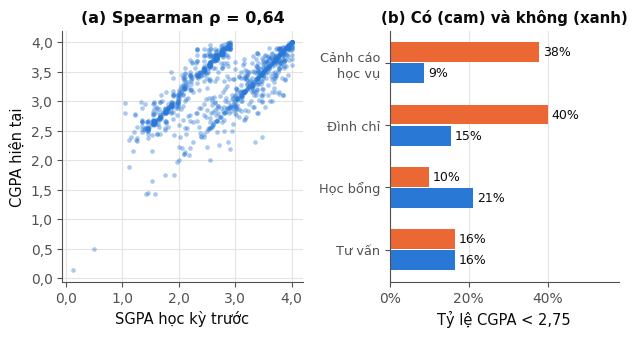

**t_leakage_evidence.csv**

,variable,label,n_yes,rate_yes,rate_no,or,or_lo,or_hi,p
0,probation_bin,Từng bị cảnh cáo học vụ,270,0.378,0.087,6.352,4.458,9.049,0.0
1,suspension_bin,Từng bị đình chỉ,40,0.400,0.155,3.638,1.888,7.010,0.0
2,scholarship_bin,Có học bổng thành tích,417,0.098,0.211,0.408,0.280,0.596,0.0
3,consultancy_bin,Đã tham gia tư vấn,540,0.165,0.164,1.004,0.720,1.401,1.0


In [31]:
part_e_leakage()
display(Markdown("**t_leakage_evidence.csv**"))
display(pd.read_csv(TAB / "t_leakage_evidence.csv").round(3))

### 6.8. Phần F: mức sẵn sàng cho AQ4 đến AQ7

Phần F không huấn luyện mô hình mà kiểm tra điều kiện để mô hình hóa ở Milestone 4 có ý nghĩa:

* **AQ4:** tỷ lệ dương, số sự kiện trên mỗi tham số (EPV) và số ca dương mỗi fold.
* **AQ5:** hệ số phóng đại phương sai (VIF) của các biến lõi để đánh giá đa cộng tuyến khi rút gọn bộ tín hiệu.
* **AQ6:** quy mô và số ca dương của từng phân nhóm giới tính và nơi ở, cùng độ rộng khoảng tin cậy kỳ vọng của recall.
* **AQ7:** giới hạn lý thuyết theo mô hình chuẩn song biến cùng phương sai (binormal): AUC tối thiểu cần có để đạt recall 60% tại trần gắn cờ 15% và 30%, và trần precision tương ứng.
* **Độ nhạy:** lặp lại kết quả chính trên mẫu B để kiểm tra kết luận có phụ thuộc quyết định loại cặp lặp hay không.

In [32]:
def part_f_readiness() -> None:
    p = float(prim["y"].mean())
    n_pos = int(prim["y"].sum())
    n_feat = len(CORE_FEATURES)
    R["readiness"] = {"prevalence": p, "n_pos": n_pos, "n_neg": int(len(prim) - n_pos), "epv": n_pos / n_feat,
                      "n_features": n_feat, "n_items": 12,
                      "pos_per_fold": prim.groupby("cv_fold_primary")["y"].sum().astype(int).to_dict(),
                      "n_per_fold": prim.groupby("cv_fold_primary").size().astype(int).to_dict()}

    # Đa cộng tuyến (VIF) trên 12 biến lõi
    X = prim[CORE_FEATURES].astype(float)
    Z = (X - X.mean()) / X.std(ddof=0)
    corr = np.corrcoef(Z.to_numpy(), rowvar=False)
    vif = np.diag(np.linalg.inv(corr))
    tv = pd.DataFrame({"variable": CORE_FEATURES, "vif": vif}).sort_values("vif", ascending=False)
    tv.to_csv(TAB / "t_vif_core.csv", index=False)
    R["vif"] = tv.to_dict(orient="records")

    # Quy mô nhóm con cho kiểm định công bằng (AQ6)
    rows = []
    for col, lab in [("gender_a", "Giới tính"), ("living_a", "Nơi ở")]:
        for k, g in prim.groupby(col):
            kk, nn = int(g["y"].sum()), len(g)
            lo, hi = wilson(kk, nn)
            rows.append({"attribute": lab, "group": k, "n": nn, "positives": kk, "rate": kk / nn, "lo": lo, "hi": hi,
                         "recall_ci_halfwidth_if_recall60": 1.96 * np.sqrt(0.6 * 0.4 / kk)})
    ts = pd.DataFrame(rows)
    ts.to_csv(TAB / "t_subgroup_size.csv", index=False)
    R["subgroups"] = rows
    gct = pd.crosstab(prim["gender_a"], prim["y"])
    lct = pd.crosstab(prim["living_a"], prim["y"])
    R["subgroup_tests"] = {"gender_p": float(stats.chi2_contingency(gct)[1]), "living_p": float(stats.chi2_contingency(lct)[1])}

    # Sàn lý thuyết: AUC cần có để đạt recall 60% tại trần gắn cờ (giả định chuẩn song biến, phương sai bằng nhau)
    from scipy.optimize import brentq
    from scipy.stats import norm
    pb = []
    for auc in [0.65, 0.70, 0.75, 0.80, 0.85, 0.90]:
        dprime = np.sqrt(2) * norm.ppf(auc)
        row = {"auc": auc}
        for fr_ in (0.15, 0.30):
            g = lambda fpr: p * norm.cdf(dprime + norm.ppf(fpr)) + (1 - p) * fpr - fr_
            fpr = brentq(g, 1e-9, 1 - 1e-9)
            row[f"recall_at_flag_{int(fr_ * 100)}"] = float(norm.cdf(dprime + norm.ppf(fpr)))
        pb.append(row)
    pd.DataFrame(pb).to_csv(TAB / "t_aq7_binormal.csv", index=False)
    R["aq7_binormal"] = pb
    auc_need = {}
    for fr_ in (0.15, 0.30):
        fpr = (fr_ - 0.6 * p) / (1 - p)
        dprime = norm.ppf(0.6) - norm.ppf(fpr)
        auc_need[str(int(fr_ * 100))] = float(norm.cdf(dprime / np.sqrt(2)))
    R["aq7_auc_needed"] = auc_need

    # Giới hạn lý thuyết của precision cho AQ7
    flag = np.arange(0.05, 0.41, 0.01)
    prec_min = 0.6 * p / flag
    lift_min = 0.6 / flag
    tab = pd.DataFrame({"flag_rate": [0.10, 0.15, 0.20, 0.25, 0.30]})
    tab["min_precision_for_recall60"] = 0.6 * p / tab["flag_rate"]
    tab["min_lift"] = 0.6 / tab["flag_rate"]
    tab["flagged_n_of_1015"] = (tab["flag_rate"] * len(prim)).round().astype(int)
    tab["true_pos_needed"] = np.ceil(0.6 * n_pos).astype(int)
    tab.to_csv(TAB / "t_aq7_feasibility.csv", index=False)
    R["aq7"] = tab.to_dict(orient="records")

    fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.6), gridspec_kw={"width_ratios": [1, 1.15]})
    ts2 = ts.copy()
    labels = [f"{r.attribute}\n{r.group}" for r in ts2.itertuples()]
    axes[0].bar(range(len(ts2)), ts2["positives"], color=BLUE, width=0.62)
    for i, v in enumerate(ts2["positives"]):
        axes[0].text(i, v + 2, str(v), ha="center", fontsize=10)
    axes[0].axhline(30, color=ORANGE, lw=1.4, ls="--")
    axes[0].set_ylim(0, 125)
    axes[0].legend(handles=[plt.Line2D([0], [0], color=ORANGE, lw=1.4, ls="--")], labels=["Mốc 30 ca dương"],
                   loc="upper center", frameon=False, fontsize=9)
    axes[0].set_xticks(range(len(ts2)))
    axes[0].set_xticklabels(labels, fontsize=8.6)
    axes[0].set_title("(a) Ca dương theo nhóm con")
    axes[0].set_ylabel("Số ca dương")
    axes[0].grid(axis="x", visible=False)
    axes[1].plot(flag * 100, prec_min * 100, color=BLUE, lw=2.4)
    axes[1].axhline(p * 100, color=INK2, lw=1.3, ls=":")
    axes[1].text(40, p * 100 + 2, f"Gắn cờ ngẫu nhiên: {vi(p * 100, 1)}%", ha="right", fontsize=9)
    for fr_, col in [(0.15, ORANGE), (0.30, ORANGE)]:
        yv = 0.6 * p / fr_ * 100
        axes[1].scatter([fr_ * 100], [yv], color=col, s=55, zorder=5, edgecolor="white", linewidths=1)
        axes[1].text(fr_ * 100 + 1.2, yv + 3, f"{vi(yv, 0)}%", fontsize=9.6)
    axes[1].set_title("(b) Precision tối thiểu")
    axes[1].set_xlabel("Tỷ lệ gắn cờ")
    axes[1].set_ylabel("Precision để đạt recall 60%")
    axes[1].xaxis.set_major_formatter(pct_axis())
    axes[1].yaxis.set_major_formatter(pct_axis())
    axes[1].set_ylim(0, 105)
    fig.tight_layout()
    save(fig, "fig15_readiness.png")

    # Nhạy cảm: lặp lại kết quả chính trên mẫu B
    rows = []
    for v in CORE_AQ2 + ["english_level", "semester_capped", "credits_completed"]:
        a, b = sensB.loc[sensB["y"] == 1, v].dropna().to_numpy(float), sensB.loc[sensB["y"] == 0, v].dropna().to_numpy(float)
        rows.append({"variable": v, "ps_B": prob_superiority(a, b), "p_B": float(stats.mannwhitneyu(a, b)[1])})
    tr = pd.DataFrame(rows)
    ref = pd.concat([pd.DataFrame(R["aq2"])[["variable", "ps"]], pd.DataFrame(R["aq3_numeric"])[["variable", "ps"]]])
    tr = tr.merge(ref.rename(columns={"ps": "ps_primary"}), on="variable", how="left")
    tr["delta"] = tr["ps_B"] - tr["ps_primary"]
    tr.to_csv(TAB / "t_sensitivity_B.csv", index=False)
    R["sensitivity_B"] = tr.to_dict(orient="records")

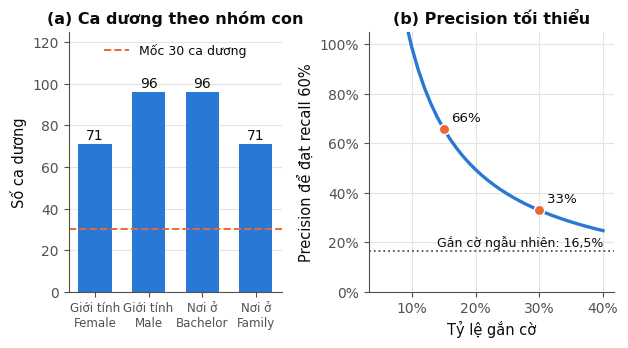

**t_vif_core.csv**

,variable,vif
0,credits_completed,8.149
1,semester_capped,7.750
2,study_hours,1.201
3,english_basic,1.192
4,study_sessions,1.186
5,english_advance,1.168
6,skill_hours,1.065
7,social_hours,1.064
8,attendance_pct,1.045
9,learning_mode_online,1.029


**t_subgroup_size.csv**

,attribute,group,n,positives,rate,lo,hi,recall_ci_halfwidth_if_recall60
0,Giới tính,Female,453,71,0.157,0.126,0.193,0.114
1,Giới tính,Male,562,96,0.171,0.142,0.204,0.098
2,Nơi ở,Bachelor,475,96,0.202,0.168,0.241,0.098
3,Nơi ở,Family,540,71,0.131,0.106,0.163,0.114


**t_aq7_binormal.csv**

,auc,recall_at_flag_15,recall_at_flag_30
0,0.65,0.274,0.469
1,0.70,0.324,0.532
2,0.75,0.381,0.599
3,0.80,0.445,0.671
4,0.85,0.518,0.747
5,0.90,0.604,0.830


**t_aq7_feasibility.csv**

,flag_rate,min_precision_for_recall60,min_lift,flagged_n_of_1015,true_pos_needed
0,0.10,0.987,6.0,102,101
1,0.15,0.658,4.0,152,101
2,0.20,0.494,3.0,203,101
3,0.25,0.395,2.4,254,101
4,0.30,0.329,2.0,304,101


**t_sensitivity_B.csv**

,variable,ps_B,p_B,ps_primary,delta
0,study_hours,0.472,0.231,0.470,0.002
1,study_sessions,0.502,0.916,0.502,0.000
2,attendance_pct,0.395,0.000,0.395,0.001
3,social_hours,0.546,0.051,0.533,0.013
4,skill_hours,0.481,0.409,0.480,0.001
5,english_level,0.476,0.260,0.466,0.010
6,semester_capped,0.540,0.098,0.526,0.014
7,credits_completed,0.531,0.192,0.511,0.020


In [33]:
part_f_readiness()
display(Markdown("**t_vif_core.csv**"))
display(pd.read_csv(TAB / "t_vif_core.csv").round(3))
display(Markdown("**t_subgroup_size.csv**"))
display(pd.read_csv(TAB / "t_subgroup_size.csv").round(3))
display(Markdown("**t_aq7_binormal.csv**"))
display(pd.read_csv(TAB / "t_aq7_binormal.csv").round(3))
display(Markdown("**t_aq7_feasibility.csv**"))
display(pd.read_csv(TAB / "t_aq7_feasibility.csv").round(3))
display(Markdown("**t_sensitivity_B.csv**"))
display(pd.read_csv(TAB / "t_sensitivity_B.csv").round(3))

### 6.9. Lưu kết quả EDA

Toàn bộ con số được dùng trong báo cáo được lưu vào `reports/milestone3/eda_results.json`.

In [34]:
with open(ROOT / "reports" / "milestone3" / "eda_results.json", "w", encoding="utf-8") as f:
    json.dump(R, f, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Hoàn tất EDA:", len(list(FIG.glob("*.png"))), "hình,", len(list(TAB.glob("*.csv"))), "bảng")

Hoàn tất EDA: 15 hình, 21 bảng


## 7. Kiểm tra tái lập và tóm tắt kết quả

### 7.1. Đối chiếu với gói dữ liệu đã nộp

Ô dưới đây so sánh mã băm SHA-256 của từng tệp do notebook tạo ra với tệp tương ứng trong gói `M3_Prepared_Data_Package` đã nộp kèm báo cáo. Kết quả được tạo với pandas 3.0 và scikit-learn 1.9; nếu môi trường dùng phiên bản khác, một vài tệp có thể khác ở cách ghi số (ví dụ số chữ số thập phân) dù nội dung không đổi. Vì vậy, ngoài mã băm, ô này còn kiểm tra các bất biến về nội dung: số dòng, số ca dương theo từng ngưỡng và cân bằng fold.

In [35]:
EXPECTED_SHA256 = {
    "data/processed/m3_analytic_master.csv": "0cc36d4f5175a64b54e7943ef4a5874cf9d8893bff3f0229ac8fa260b4d3e1c6",
    "data/processed/m3_analytic_primary_model.csv": "5ee373340359f46d9ef286c6ff029b05aa0e3e7eb4bdb06a15e5765affeb4503",
    "data/processed/m3_audit_groups.csv": "6e13acd36a31f95139e4caf326cf7e5199e7bcaebe5188513075d2adfe12acc8",
    "data/interim/m3_typed_standardized.csv": "a2012f6c1b81e45ce36964e249c988ee0a34f77551d37bccfa8f5225f67ecdb6",
    "data/metadata/data_dictionary_m3.csv": "4c817dc4a8fcf400d617bcf7ce6a1d4b523961a820bef03f9272523e1cce0a24",
    "data/metadata/data_lineage_m3.csv": "fb4cd17bedea9e30e51842706a296d6c0ffc7928396bb08f436b667b4d52a58f",
    "data/metadata/quality_issue_log_m3.csv": "476546fe4a6c09dd062a9208d58a5204513b680978100c697d6d4e944071b90c",
    "data/metadata/transformation_log_m3.csv": "fae369a93f605c2d8eeb1517e9a787f77e23d6f76ea0939788e73696302b0267",
    "reports/milestone3/tables/t_aq1_by_cohort.csv": "c2762df17903ccbf0510217b1e02263ab0eccd81ee71aedff2828d1ea1babdb8",
    "reports/milestone3/tables/t_aq1_by_semband.csv": "2a30f64a381cb57862c1e7b2fdc3d9e629024152538dc1340318d5b6700ec329",
    "reports/milestone3/tables/t_aq1_prevalence.csv": "7b3238d05e4f5f5d9f74f50e828f9278befbb5e000bb132196bb279876838e02",
    "reports/milestone3/tables/t_aq2_att_study_counts.csv": "83641183cfd5bd51ef6be924dca9db5245ef81e3af15bd03db7e39c7f71a832b",
    "reports/milestone3/tables/t_aq2_att_study_matrix.csv": "8090a6d9b8fb461d8232387a8983cdc538610ee448836e156a092cbad9370db9",
    "reports/milestone3/tables/t_aq2_attendance_bins.csv": "10e083d8d6bfdcbc29d9470319ff542218c03cd9a695f5cf096bceb38610410d",
    "reports/milestone3/tables/t_aq2_attendance_by_semband.csv": "894303f3bbc3d24332552584ac439f023cdd8892918c631b0524dda2c78fdc50",
    "reports/milestone3/tables/t_aq2_numeric.csv": "f91d6098ba64cf4fc050a715151cf3e8e621b746bb90ccd54b750223dfeaa2c9",
    "reports/milestone3/tables/t_aq3_binary.csv": "29c273c402e447bc0971535ed08f2c35a4bebf6d2ce285955dfbb80ca1705628",
    "reports/milestone3/tables/t_aq3_numeric.csv": "2d0308e4f7f112a48bb293279abca885e1addddf4a6485eb49ef6e863c9667bd",
    "reports/milestone3/tables/t_aq7_binormal.csv": "b69f09ef8e31c3ded3495b7d703fd9f94ea5e37ac9d0f0fdd9da75df8763a262",
    "reports/milestone3/tables/t_aq7_feasibility.csv": "09f512cc9baeb4f4a332046e3e397ab72c4297b91ff6d43db4c715c782da7ee6",
    "reports/milestone3/tables/t_composition_shift.csv": "0c15defde6ffcaf7121d191b1e02bc8adf1980059af94b246c5cdfefcfba4eca",
    "reports/milestone3/tables/t_descriptive_primary.csv": "3d878698e576dfdd4b5377968333878d813542363db1c4707ef4672fc4c6f56e",
    "reports/milestone3/tables/t_forest_ps.csv": "93fa082d0b840c590addbafad9a93d1ab8caa9aa4aef1e33edfbd9edb6f0fca9",
    "reports/milestone3/tables/t_leakage_evidence.csv": "ee78ba0e3116719a6d976cfd95479221ffdd1a9ad1b9bd0f67973a990f4403d8",
    "reports/milestone3/tables/t_placeholder_vs_rest.csv": "4718fbeea60f8f247c13cb25839cccf48cb7d0b2adea6a94411ff480604af585",
    "reports/milestone3/tables/t_sensitivity_B.csv": "89af3b192a9cb7abaad57fe191f1f8182a39d952e69484144bf81bcea6eeb40f",
    "reports/milestone3/tables/t_spearman_matrix.csv": "68545adf7d53dacc6d6c8aef1a70f39243a0204f0ecfb1fc33323bdd760c0c2a",
    "reports/milestone3/tables/t_subgroup_size.csv": "3c1017046ce4c88c5b6f043eefda439bd600e0d75aa3ed4905138c9dbe1c626b",
    "reports/milestone3/tables/t_vif_core.csv": "e47d6ae231f555a274e2dc4abd27c74c4b17dfc5677024584f72dc1008e16eb9",
}
rows = []
for rel, h in EXPECTED_SHA256.items():
    p = ROOT / rel
    rows.append({"Tệp": rel, "Tồn tại": p.exists(), "Trùng từng byte": p.exists() and sha256_of(p) == h})
check = pd.DataFrame(rows)
display(check)
print(f"Trùng từng byte: {int(check['Trùng từng byte'].sum())}/{len(check)} tệp")

prim_file = pd.read_csv(processed / "m3_analytic_primary_model.csv")
assert len(prim_file) == 1015 and prim_file.shape[1] == 18
assert prim_file[["y_lt_2_50", "y_lt_2_75", "y_lt_3_00"]].sum().tolist() == [52, 167, 311]
assert prim_file.groupby("cv_fold_primary")["y_lt_2_75"].sum().tolist() == [33, 33, 33, 34, 34]
assert prim_file[CORE_FEATURES].isna().sum().sum() == 0
print("Các bất biến nội dung của Prepared Dataset v1.0 đều đạt.")

,Tệp,Tồn tại,Trùng từng byte
0,data/processed/m3_analytic_master.csv,True,True
1,data/processed/m3_analytic_primary_model.csv,True,True
2,data/processed/m3_audit_groups.csv,True,True
3,data/interim/m3_typed_standardized.csv,True,True
4,data/metadata/data_dictionary_m3.csv,True,True
5,data/metadata/data_lineage_m3.csv,True,True
6,data/metadata/quality_issue_log_m3.csv,True,True
7,data/metadata/transformation_log_m3.csv,True,True
8,reports/milestone3/tables/t_aq1_by_cohort.csv,True,True
9,reports/milestone3/tables/t_aq1_by_semband.csv,True,True


Trùng từng byte: 24/29 tệp
Các bất biến nội dung của Prepared Dataset v1.0 đều đạt.


### 7.2. Tóm tắt kết quả chính

* **Prepared Dataset v1.0.** Từ 1.194 phiếu, 39 dòng CGPA bằng 0 không có nhãn và 140 dòng thuộc cặp lặp 2,68/3,15 bị loại khỏi mẫu chính, còn 1.015 sinh viên với 167 ca dương (16,5%) ở ngưỡng 2,75. Mẫu độ nhạy B giữ cặp lặp (1.155 sinh viên). Tệp mô hình gồm 13 đặc trưng lõi từ 12 mục khảo sát, không chứa biến rò rỉ hay biến nhạy cảm, không có giá trị khuyết.
* **AQ1.** Tỷ lệ nhóm cần hỗ trợ ở ba ngưỡng 2,50, 2,75 và 3,00 lần lượt khoảng 5%, 16,5% và 31% trên mẫu chính; ngưỡng 2,75 cho số ca dương đủ cho kiểm định chéo và kiểm định công bằng.
* **AQ2.** Trong năm thói quen tự báo cáo, chuyên cần là tín hiệu có hướng rõ ràng nhất (chuyên cần thấp đi kèm tỷ lệ cần hỗ trợ cao hơn); các biến giờ học, số lần ngồi học, giờ mạng xã hội và giờ phát triển kỹ năng có độ lớn hiệu ứng nhỏ.
* **AQ3.** Trình độ tiếng Anh có quan hệ chữ U với nhãn (Basic và Advance cao hơn Intermediate), nên được mã hóa bằng hai biến giả. Học kỳ và số tín chỉ tương quan rất mạnh, cần xử lý đa cộng tuyến ở Milestone 4.
* **Rò rỉ.** Cảnh cáo học vụ, đình chỉ, học bổng, tư vấn và SGPA liên hệ rất mạnh với nhãn và bị loại khỏi tập đặc trưng.
* **Mức sẵn sàng AQ4 đến AQ7.** EPV khoảng 12,8 và 33 đến 34 ca dương mỗi fold cho phép một mô hình đơn giản; ca dương theo phân nhóm chỉ 71 đến 96 nên kết luận công bằng sẽ có khoảng tin cậy rộng. Theo giới hạn binormal, đạt recall 60% tại trần gắn cờ 30% cần AUC khoảng 0,75, và tại trần 15% cần AUC khoảng 0,90; đây là kỳ vọng thận trọng được mang sang Milestone 4.

Các con số chi tiết nằm trong các bảng đã hiển thị ở Mục 6 và trong `eda_results.json`.